# Averaging — Theorem 6·7과 Table 2

[공통 분석 파이프라인](00_Common_analysis_pipeline.ipynb) · [앞선 SGD 분석](3_2_2_Figure_2_2A_StochasticGradientDescent.ipynb) · [SGD with averaging 원본 코드](../2_Stochastic_BoundedVariance/B_StochasticGradientDescentWithAveraging.py) · [Primal averaging 원본 코드](../2_Stochastic_BoundedVariance/C_StochasticGradientDescentWithPrimalAveraging.py) · [논문](https://proceedings.mlr.press/v99/taylor19a.html)

수치 실험의 함수값 계수는 원본 Python 코드의 $d_k$로 쓴다. Theorem 6을 인용하는 부분의 $d_k$는 논문에 따라 평균 가중치를 뜻하며, 그 문맥에서 현재 함수값 계수는 $L\delta_kd_k$다.

앞선 SGD 분석에서 얻은 결과를 출발점으로 삼자. Theorem 5에 고정 step-size $\delta_k=1/L$를 적용하면

$$d_N=N,\qquad e_k=\frac{k+2}{2L},\qquad
\sum_{k=0}^{N-1}e_k=\frac{N(N+3)}{4L}.$$

함수값 계수는 $O(N)$으로 증가하지만, 오차 계수의 누적합은 $O(N^2)$으로 증가한다. 따라서 최종 함수값 상한에서 분산에 곱해지는 계수 $(\sum e_k)/d_N$은 $O(N)$으로 커진다. **마지막 반복점 대신 평균점을 사용하면, 함수값 계수의 증가를 유지하면서 오차 계수의 누적합이 커지는 속도를 낮출 수 있을까?**

SGD에서 사용한 매끄러운 볼록함수와 bounded variance 가정, Gram 표현을 통한 LMI/SDP 구성은 그대로 사용한다. 최종 상한에서는 앞서와 마찬가지로 $(\sum e_k)/d_N$이 분산 항의 크기를 결정한다. 이번에 바꾸는 것은 평균점을 만드는 방법과 oracle의 평가점이다. 공통 파이프라인의 다섯 단계를 두 알고리즘에 각각 적용한 뒤, 마지막에는 각 정리의 계수 합을 이용해 Table 2의 수렴률을 비교한다.

| 공통 단계 | A. SGD with averaging | B. Primal averaging |
| --- | --- | --- |
| 1단계 · 알고리즘과 가정 | SGD 갱신 뒤에 평균을 계산하면 무엇이 달라지는가? | 평균점을 먼저 정하고 그 점에서 oracle을 평가하면 무엇이 달라지는가? |
| 2단계 · Parameterized potential 설정 | $z_k$의 함수값과 $x_k$의 거리항을 어떻게 함께 담는가? | $y_k$의 함수값과 $x_k$의 거리항을 어떻게 함께 담는가? |
| 3단계 · LMI/SDP로 계수 수치 탐색 | $d_N$을 키운 뒤 오차 계수의 누적합을 얼마나 줄일 수 있는가? | 알고리즘이 정한 $d_k$를 유지하면서 오차 계수의 누적합을 얼마나 줄일 수 있는가? |
| 4단계 · 계수 패턴 관찰과 단순화 | 단순한 potential에서도 $e_k$의 증가를 억제할 수 있는가? | 추가 오차 항 없이 일정한 $e_k$를 얻을 수 있는가? |
| 5단계 · 해석적 potential inequality와 수렴률 | 관찰한 구조를 Theorem 6으로 어떻게 증명하는가? | 관찰한 구조를 Theorem 7로 어떻게 증명하는가? |

## A. SGD with averaging

### 1단계 · 알고리즘과 가정

먼저 SGD 갱신 뒤에 새 반복점을 기존 평균에 반영한다.

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad
z_{k+1}^{(i)}=\frac{x_{k+1}^{(i)}+kz_k}{k+1},\qquad
\delta_k=\frac1L.$$

이 과정을 반복하면 $z_N$은 $x_1,\ldots,x_N$의 산술평균이 된다. 일반적인 SGD와 같은 점 $x_k$에서 oracle을 평가하지만, 함수값을 분석할 출력은 $x_N$에서 $z_N$으로 바뀐다.

가정은 앞선 SGD와 같다. $f\in\mathcal F_L$, $f_\star=f(x_\star)$이고, stochastic oracle은

$$\mathbb E_iG(v;i)=f'(v),\qquad
\mathbb E_i\|G(v;i)-f'(v)\|^2\le\sigma^2$$

를 만족한다. 아래 수치 모형은 원본 averaging 코드를 따른다. 수식의 상태 $k$는 코드의 상태 인덱스 `k+1`에 대응하므로, 업데이트 루프 `k=1,...,N`은 수식의 $0\to1,\ldots,N-1\to N$을 나타낸다.

알고리즘과 출력점을 정했으므로, 다음 단계에서는 $z_k$의 함수값과 $x_k$의 거리항을 함께 담을 potential을 선택한다.


In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util

import cvxpy as cp
import matplotlib.pyplot as plt
import mosek
import numpy as np
from IPython.display import Markdown, display

repo_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "2_Stochastic_BoundedVariance/B_StochasticGradientDescentWithAveraging.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Repository root not found.")
license_path = repo_root / "mosek.lic"
if license_path.is_file():
    mosek.Env().putlicensepath(str(license_path))

adapter_path = repo_root / "2_Stochastic_BoundedVariance/saveData.py"
spec = importlib.util.spec_from_file_location("averaging_saveData", adapter_path)
solver_adapter = importlib.util.module_from_spec(spec)
spec.loader.exec_module(solver_adapter)
solve = solver_adapter.solve

### 2단계 · Parameterized potential 설정

1단계에서 정한 출력은 평균점 $z_k$이고, SGD 갱신은 $x_k$에서 이루어진다. 두 상태를 함께 담기 위해 다음 형태의 potential을 사용한다. 이 절에서는 평균점 $z_k$를 그대로 쓴다.

$$\phi_k^f=a_k\|z_k-x_\star\|^2+b_k\|f'(z_k)\|^2
+2c_k\langle f'(z_k),z_k-x_\star\rangle
+d_k(f(z_k)-f_\star)+a'_k\|x_k-x_\star\|^2.$$

평균점과 최적점 사이의 거리 제곱, gradient norm 제곱, 두 벡터의 내적에 관한 항은 $Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$로 묶는다. 함수값은 평균점에서 평가하고, 별도의 거리항은 SGD 반복점에서 평가한다. 코드의 `d[k+1]`은 함수값 계수 $d_k$, `ap[k+1]`은 거리항 계수 $a'_k$에 대응한다.

중간 계수 제약과 $\phi_N^f$의 경계조건이 다른 두 SDP를 비교한다. 공통으로 $Q_0=Q_N=0$, $d_0=0$, $a'_0=L/2$이다.

| `relax` | 중간 계수 ($1\le k<N$) | $\phi_0^f$ | $\phi_N^f$ |
| --- | --- | --- | --- |
| 0 | $Q_k,d_k,a'_k$ 자유 | $\frac L2\|x_0-x_\star\|^2$ | $d_N(f(z_N)-f_\star)$ |
| 1 | $Q_k=0,\ a'_k=L/2$, $d_k$ 자유 | $\frac L2\|x_0-x_\star\|^2$ | $d_N(f(z_N)-f_\star)+\frac L2\|x_N-x_\star\|^2$ |


각 단계에서

$$\mathbb E_i\phi_{k+1}^f\le\phi_k^f+e_k\sigma^2$$

를 만족하면 telescoping으로 중간 potential이 소거된다. $\phi_N^f$의 비음수 항 $a'_N\|x_N-x_\star\|^2$을 제외하고 $d_N>0$으로 나누면

$$\mathbb E[f(z_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2d_N}
+\frac{\sum_{k=0}^{N-1}e_k}{d_N}\sigma^2$$

를 얻는다. 이 상한을 바탕으로 다음 단계의 목적함수를 정한다. 먼저 $d_N$을 크게 만들고, 그 수준을 유지하면서 $\sum e_k$를 줄인다. 수치 결과를 비교할 때도 최종 상한에 들어가는 비율 $(\sum e_k)/d_N$을 함께 비교한다.

아래 실험의 기본 설정은

$$L=1,\qquad \mu=0,\qquad n=2,\qquad N=100$$

이다. Potential과 경계 조건을 정했으므로, 이제 한 단계에서의 potential 변화에 대한 부등식을 Gram 표현으로 옮겨 LMI/SDP를 구성한다.


In [2]:
L = 1.0
m = 0.0
n = 2
N_FIGURE = 100
solver = "MOSEK"
tolerance = 1e-8
tol_reopt = 1e-5
verbose = False

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 11,
})

### 3단계 · LMI/SDP로 계수 수치 탐색

2단계의 potential과 경계 조건을 SDP의 변수와 제약으로 옮긴다. 현재·다음 potential 차이를 Gram 행렬과 함수값의 선형식으로 쓰고, interpolation 부등식과 분산 조건의 비음수 가중합을 더한다.

#### 한 단계의 Gram 표현

$x_\star=f_\star=0$으로 옮기면 $f'(x_\star)=0$이다. 원본 2B 코드의 배치대로

$$P=[x_k\quad z_k\quad f'(z_k)\quad G(x_k;1)\ \cdots\ G(x_k;n)
\quad f'(z_{k+1}^{(1)})\ \cdots\ f'(z_{k+1}^{(n)})],\qquad G=P^\top P$$

로 모은다. 아래 코드는 $P$의 열을 고르는 원본 계수벡터 `xk`, `zk`, `gzk`, `Gxk`, `gxk`, `gzk1`을 만든다. $n=2$이면 $G$는 7×7이다.


In [3]:
N = N_FIGURE
alpha = 0
delta = lambda k: 1 / L / (k + 1)**alpha
dimG = 3 + 2 * n
dimF = n + 2
nbPts = 3 + n

xk = np.zeros(dimG)
xk[0] = 1
zk = np.zeros(dimG)
zk[1] = 1
xs = np.zeros(dimG)
gzk = np.zeros(dimG)
gzk[2] = 1
Gxk = np.zeros((n, dimG))
Gxk[:, 3:n + 3] = np.eye(n)
gxk = np.sum(Gxk, axis=0) / n
gzk1 = np.zeros((n, dimG))
gzk1[:, 3 + n:3 + 2 * n] = np.eye(n)
gxs = np.zeros(dimG)


함수값은 논문과 같은 **행벡터**로 모은다.

$$F=[f(z_k),f(x_k),f(z_{k+1}^{(1)}),\ldots,f(z_{k+1}^{(n)})].$$

원본 변수 `fzk`, `fxk`, `fzk1[i-1]`은 각각의 성분을 고른다. 예를 들어 $F\mathtt{fzk}=f(z_k)$이다. 다음 반복점과 평균점은 원본 `xk1`, `zk1`로 계산하며 $P$의 새 열을 추가하지 않는다.

코드의 인덱스는 실제 업데이트 루프처럼 1부터 시작한다. 따라서 아래 평균 갱신식의 분모는 `k`이고 기존 평균의 가중치는 `(k-1)/k`다.


In [4]:
fzk = np.zeros(dimF)
fzk[0] = 1
fxk = np.zeros(dimF)
fxk[1] = 1
fzk1 = np.zeros((n, dimF))
fzk1[:, 2:n + 2] = np.eye(n)
fxs = np.zeros(dimF)

xk1 = lambda k: np.ones((n, 1)) * xk - delta(k) * Gxk
zk1 = lambda k: xk1(k) / k + (k - 1) / k * zk
statesKG = np.column_stack((zk - xs, gzk))
statesKF = fzk


#### Interpolation 부등식과 분산 조건을 Gram 행렬로 표현하기

논문의 식 (19)는 위치·gradient·함수값의 계수벡터 $x_i,g_i,f_i$를 사용해

$$F(f_i-f_j)+\operatorname{Tr}(GM_{i,j})\ge0,$$
$$M_{i,j}=[x_i\ x_j\ g_i\ g_j]M[x_i\ x_j\ g_i\ g_j]^\top$$

로 interpolation 조건을 표현한다. 여기서 $Px_i,Pg_i,Ff_i$가 실제 위치·gradient·함수값이며, $M$은 아래 원본 코드의 행렬이다. 코드의 `TT = np.vstack((X[i], X[j], G[i], G[j]))`는 위 열벡터 네 개를 행으로 쌓는다. 따라서 `TT.T @ M @ TT`가 $M_{i,j}$다.

분산 행렬은 논문의 $A_{\rm var}$와 원본 코드의 `Avar`에 해당한다.

$$A_{\rm var}=\frac1n\sum_i
(\mathtt{Gxk}[i-1]-\mathtt{gxk})
(\mathtt{Gxk}[i-1]-\mathtt{gxk})^\top,
\qquad\operatorname{Tr}(GA_{\rm var})\le\sigma^2.$$

`gxk`는 oracle 계수벡터들의 평균이므로 $P\mathtt{gxk}=f'(x_k)$이고, unbiasedness가 이 표현에 반영된다.


In [5]:
M = np.array([
    [-L * m, L * m, m, -L],
    [L * m, -L * m, -m, L],
    [m, -m, -1, 1],
    [-L, L, 1, -1],
]) / (2 * (L - m))
Avar = np.zeros((dimG, dimG))
for i in range(1, n + 1):
    Avar = Avar + np.outer(Gxk[i - 1] - gxk, Gxk[i - 1] - gxk) / n


#### Potential 계수와 경계 조건을 코드로 정의하기

이제 2단계에서 선택한 potential의 계수와 경계 조건을 코드로 정의한다. 평균점 $z_k$를 사용하므로

$$\phi_k^f=
\begin{pmatrix}z_k-x_\star\\f'(z_k)\end{pmatrix}^{\!\top}
(Q_k\otimes I)
\begin{pmatrix}z_k-x_\star\\f'(z_k)\end{pmatrix}
+d_k(f(z_k)-f_\star)+a'_k\|x_k-x_\star\|^2,\qquad
Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$$

이다. 아래 코드에서는 두 설정의 중간 단계 계수를 변수로 선언하고, 초기·최종 경계값을 지정한다. 계수를 자유롭게 탐색하는 설정에서는 $Q_k,d_k,a'_k$를 탐색하고, 단순한 potential로 제한한 설정에서는 $Q_k=0,a'_k=L/2$로 둔 채 $d_k$를 탐색한다. 최종 경계조건은 `relax=0`에서 $\phi_N^f=d_N(f(z_N)-f_\star)$, `relax=1`에서 $\phi_N^f=d_N(f(z_N)-f_\star)+\frac L2\|x_N-x_\star\|^2$이다.

중간 단계의 $Q_k$에는 별도의 PSD 제약을 부과하지 않는다. $Q_k$는 potential의 계수행렬이며, 실제 벡터의 내적을 모은 Gram 행렬 $G\succeq0$과는 역할이 다르다. 코드의 `d`에는 함수값 계수 $d_k$가 저장된다.


In [6]:
averaging_models = {}
for relax in (0, 1):
    tau = cp.Variable(name="tau")
    Q = {1: np.zeros((2, 2)), N + 1: np.zeros((2, 2))}
    d = {1: 0, N + 1: tau}
    ap = {1: L / 2, N + 1: 0 if relax == 0 else L / 2}
    lam, e = {}, {}
    for k in range(1, N + 1):
        if k < N:
            d[k + 1] = cp.Variable(name=f"d_{k + 1}")
            ap[k + 1] = cp.Variable(name=f"ap_{k + 1}") if relax == 0 else L / 2
            Q[k + 1] = (cp.Variable((2, 2), symmetric=True, name=f"Q_{k + 1}")
                      if relax == 0 else np.zeros((2, 2)))
        lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")
        e[k] = cp.Variable(name=f"e_{k}")
    averaging_models[relax] = {
        "tau": tau, "Q": Q, "d": d, "ap": ap, "lam": lam, "e": e,
        "cons_SDP": {}, "cons_LIN": {}, "cons": [tau >= 0],
    }


#### 한 단계 potential 차이의 행렬을 만들기

논문의 $V_k,V_{k+1}^{(i)}$를 원본 코드의 `statesKG`, `statesK1G`, `XK1`로 구성한다.

$$V_k=\mathtt{statesKG}\,Q_k\mathtt{statesKG}^{\top}
+a'_k(\mathtt{xk}-\mathtt{xs})(\mathtt{xk}-\mathtt{xs})^\top,$$
$$V_{k+1}^{(i)}=\mathtt{statesK1G}\,Q_{k+1}\mathtt{statesK1G}^{\top}
+a'_{k+1}(\mathtt{XK1}[i-1]-\mathtt{xs})(\mathtt{XK1}[i-1]-\mathtt{xs})^\top.$$

`statesK1G`는 각 outcome의 루프에서 구성한다. 아래에서는 먼저

$$\frac1n\sum_iV_{k+1}^{(i)}-V_k-e_kA_{\rm var}$$

를 원본 변수 `cons_SDP[k]`에, 함수값 계수의 차이를 `cons_LIN[k]`에 구성한다. 다음 셀에서 interpolation 부등식의 가중합을 더한다.


In [7]:
for relax, model in averaging_models.items():
    Q, d, ap, e = (model[key] for key in ("Q", "d", "ap", "e"))
    cons_SDP, cons_LIN = model["cons_SDP"], model["cons_LIN"]
    for k in range(1, N + 1):
        XK1, ZK1 = xk1(k), zk1(k)
        cons_SDP[k] = -statesKG @ Q[k] @ statesKG.T
        cons_SDP[k] = cons_SDP[k] - ap[k] * np.outer(xk - xs, xk - xs) - e[k] * Avar
        cons_LIN[k] = -d[k] * statesKF
        for i in range(1, n + 1):
            statesK1G = np.column_stack((ZK1[i - 1] - xs, gzk1[i - 1]))
            statesK1F = fzk1[i - 1]
            cons_SDP[k] = cons_SDP[k] + statesK1G @ Q[k + 1] @ statesK1G.T / n
            cons_SDP[k] = cons_SDP[k] + ap[k + 1] * np.outer(XK1[i - 1] - xs, XK1[i - 1] - xs) / n
            cons_LIN[k] = cons_LIN[k] + statesK1F * d[k + 1] / n


Interpolation point는 $\{x_\star,x_k,z_k,z_{k+1}^{(1)},\ldots,z_{k+1}^{(n)}\}$이다. 서로 다른 두 점의 순서쌍마다 비음수 multiplier를 붙이면 논문의 조건은

$$\frac1n\sum_iV_{k+1}^{(i)}-V_k-e_kA_{\rm var}
+\sum_{i\ne j}\lambda_{i,j}M_{i,j}\preceq0,$$
$$\frac{d_{k+1}}n\sum_i\mathtt{fzk1}[i-1]-d_k\mathtt{fzk}
+\sum_{i\ne j}\lambda_{i,j}(\mathtt{F}[i]-\mathtt{F}[j])=0,
\qquad\lambda_{i,j}\ge0,\quad e_k\ge0$$

이다. 이 식의 `F[i]`는 원본 딕셔너리의 함수값 계수벡터다. `cons_LIN[k] == 0`으로 함수값 항을 소거하고, `cons_SDP[k] << 0`으로 남은 이차항을 제어한다. 두 potential 설정 모두 같은 7×7 LMI를 사용한다.


In [8]:
for relax, model in averaging_models.items():
    lam, e = model["lam"], model["e"]
    cons_SDP, cons_LIN, cons = (model[key] for key in ("cons_SDP", "cons_LIN", "cons"))
    for k in range(1, N + 1):
        ZK1 = zk1(k)
        X = {1: xs, 2: xk, 3: zk}
        G = {1: gxs, 2: gxk, 3: gzk}
        F = {1: fxs, 2: fxk, 3: fzk}
        for i in range(1, n + 1):
            X[3 + i], G[3 + i], F[3 + i] = ZK1[i - 1], gzk1[i - 1], fzk1[i - 1]
        for i in range(1, nbPts + 1):
            for j in range(1, nbPts + 1):
                if j != i:
                    TT = np.vstack((X[i], X[j], G[i], G[j]))
                    cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * (TT.T @ M @ TT)
                    cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * (F[i] - F[j])
        cons = cons + [cons_SDP[k] << 0, cons_LIN[k] == 0, lam[k] >= 0, e[k] >= 0]
    model["cons"] = cons


#### 함수값 계수를 키운 뒤 오차 계수의 누적합을 줄이기

먼저 위 제약 아래에서 최종 함수값 계수 $\tau=d_N$을 최대화한다. 그다음 이 값을 거의 유지하면서 $\sum_{k=0}^{N-1}e_k$를 최소화한다. 원본 코드는 첫 목적함수 `obj = -tau`를 사용하고, 두 번째 최적화 전에 `tau >= -float(obj.value) - tol_reopt`를 추가한다. 여기서 `tol_reopt = 1e-5`다.

첫 번째 최적화는 $d_N$을 크게 만들고, 두 번째 최적화는 분산 계수의 크기를 조절한다. 아래 코드는 첫 최적화를 실행하고 얻은 함수값 계수와 오차 계수의 합을 저장한다.


In [9]:
for relax, model in averaging_models.items():
    tau, e, cons = model["tau"], model["e"], model["cons"]
    accumulated_ek = 0
    for k in range(1, N + 1):
        accumulated_ek = accumulated_ek + e[k]
    obj = -tau
    solver_opt = {
        "solver": solver, "verbose": bool(verbose),
        "mosek_params": {"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance},
    }
    started = perf_counter()
    solverDetails = cp.Problem(cp.Minimize(obj), cons)
    solve(solverDetails, **solver_opt)
    model["stage1"] = {
        "d_N": -float(obj.value), "sum_e": float(accumulated_ek.value),
        "status": solverDetails.status,
    }
    model["accumulated_ek"] = accumulated_ek
    model["seconds_stage1"] = perf_counter() - started


이제 첫 번째 최적화에서 얻은 $d_N$의 하한을 제약에 추가하고 $\sum e_k$를 최소화한다. 재최적화에서는 원본 코드와 동일하게 solver의 기본 설정을 사용한다. 두 최적화의 결과는 다음 표에서 함께 비교한다.


In [10]:
for relax, model in averaging_models.items():
    tau, cons = model["tau"], model["cons"]
    cons = cons + [tau >= model["stage1"]["d_N"] - tol_reopt]
    solver_opt = {"solver": solver, "verbose": bool(verbose)}
    started = perf_counter()
    solverDetails = cp.Problem(cp.Minimize(model["accumulated_ek"]), cons)
    solve(solverDetails, **solver_opt)
    model["cons"] = cons
    model["problem"] = solverDetails
    model["seconds"] = model["seconds_stage1"] + perf_counter() - started


#### 두 차례 최적화가 상한을 어떻게 바꾸었는가?

$Q_k$에서 $a_k,b_k,c_k$를 추출하고, 단계별 $e_k$로부터 누적합 $\sum_{t=0}^{k-1}e_t$를 계산한다. 각 최적화에서 얻은 $d_N$, 오차 계수의 누적합, 그리고 함수값 상한에 들어가는 비율 $(\sum e_k)/d_N$을 함께 비교한다.


In [11]:
averaging_results = {}
for relax, model in averaging_models.items():
    Q, d, ap, e, lam = (model[key] for key in ("Q", "d", "ap", "e", "lam"))
    qvalues = np.stack([np.asarray(Q[k].value if isinstance(Q[k], cp.Expression)
                                  else Q[k]) for k in range(1, N + 2)])
    dvalues = np.array([float(d[k].value if isinstance(d[k], cp.Expression)
                             else d[k]) for k in range(1, N + 2)])
    apvalues = np.array([float(ap[k].value if isinstance(ap[k], cp.Expression)
                              else ap[k]) for k in range(1, N + 2)])
    evalues = np.array([float(e[k].value) for k in range(1, N + 1)])
    averaging_results[relax] = {
        "a": qvalues[:, 0, 0], "b": qvalues[:, 1, 1], "c": qvalues[:, 0, 1],
        "d": dvalues, "ap": apvalues, "e": evalues,
        "ec": np.r_[0., np.cumsum(evalues)],
        "multipliers": np.stack([lam[k].value for k in range(1, N + 1)]),
        "d_N": float(dvalues[-1]), "sum_e": float(evalues.sum()),
        "stage1": model["stage1"], "status": model["problem"].status,
        "N": N, "L": L, "n": n, "relax": relax, "seconds": model["seconds"],
    }


In [12]:
for relax, model in averaging_models.items():
    result = averaging_results[relax]
    matrices = np.stack([model["cons_SDP"][k].value for k in range(1, N + 1)])
    equalities = np.stack([model["cons_LIN"][k].value for k in range(1, N + 1)])
    result["residuals"] = {
        "R": matrices, "equality": equalities,
        "lmi_violation": max(0., float(np.linalg.eigvalsh(matrices).max())),
        "equality_violation": float(np.abs(equalities).max()),
        "multiplier_violation": max(0., float(-result["multipliers"].min())),
        "variance_multiplier_violation": max(0., float(-result["e"].min())),
    }
headers = ["설정", "최적화 단계", r"$d_N$", r"$\sum_{k=0}^{N-1}e_k$",
           r"$(\sum e_k)/d_N$"]
rows = []
for relax, result in averaging_results.items():
    for stage, d_final, error_sum in (
        ("1: 함수값 계수 최대화", result["stage1"]["d_N"], result["stage1"]["sum_e"]),
        ("2: 누적 오차 최소화", result["d_N"], result["sum_e"]),
    ):
        rows.append((str(relax), stage, f"{d_final:.8f}", f"{error_sum:.6f}",
                     f"{error_sum / d_final:.6f}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))
for relax, result in averaging_results.items():
    if result["status"] not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"averaging relax={relax}: {result['status']}")
    print(f"relax={relax}: {result['status']}")


| 설정 | 최적화 단계 | $d_N$ | $\sum_{k=0}^{N-1}e_k$ | $(\sum e_k)/d_N$ |
| --- | --- | --- | --- | --- |
| 0 | 1: 함수값 계수 최대화 | 102.00000086 | 5216.906032 | 51.146137 |
| 0 | 2: 누적 오차 최소화 | 101.99990306 | 48.634944 | 0.476814 |
| 1 | 1: 함수값 계수 최대화 | 100.11848875 | 28319.771650 | 282.862556 |
| 1 | 2: 누적 오차 최소화 | 100.11846808 | 52.604190 | 0.525419 |

relax=0: optimal
relax=1: optimal


`relax=1`에서 오차 계수의 누적합은 첫 번째 최적화의 약 $28319.77$에서 두 번째 최적화의 약 $52.60$으로 줄었다. 두 번째 최적화는 첫 번째 최적화에서 찾은 $d_N$을 거의 유지하면서 $\sum e_k$와 최종 상한의 분산 계수를 크게 낮춘다. 이는 $\max d_N$과 $\min\sum e_k$를 순차적으로 푸는 목적함수 선택의 효과다.

모형에 넣은 재최적화 제약은 최초 최적값에서 $10^{-5}$를 뺀 값보다 $\tau$가 크다는 조건이다. 정확히 이 제약을 만족하는 해라면 $d_N$의 감소량은 $10^{-5}$ 이하여야 한다. 저장된 수치해에서 이 차이가 조금 더 큰 것은 solver의 수치 허용오차가 포함된 결과다.

이제 최종 수치만이 아니라, 그 결과를 만든 계수 수열을 살펴본다. 자유롭게 탐색한 설정과 $Q_k=0$, $a'_k=L/2$로 제한한 설정을 비교하면, 단순한 potential로도 어떤 계수 구조를 유지할 수 있는지 볼 수 있다.


### 4단계 · 계수 패턴 관찰과 단순화

3단계에서는 두 차례 최적화로 $d_N$과 오차 계수의 누적합을 구하고, 오차 계수의 누적합을 함수값 계수로 나눈 비율도 비교했다. 이제 계수 수열의 변화를 살펴보며, 반복 횟수에 관계없이 부등식이 성립함을 증명할 수 있는 단순한 형태를 찾는다.

#### 거리항·함수값·오차 계수의 변화를 함께 보기

아래 네 패널은 $a'_k$, $d_k$, $e_k$, $\sum_{t<k}e_t$를 보여 준다. 두 설정은 최종 거리항 $a'_N$도 다르므로, 각 곡선을 비교할 때 이 경계 조건의 차이도 함께 고려해야 한다. 특히 끝부분의 거리항과 오차 계수가 함께 어떻게 바뀌는지 살펴보자.


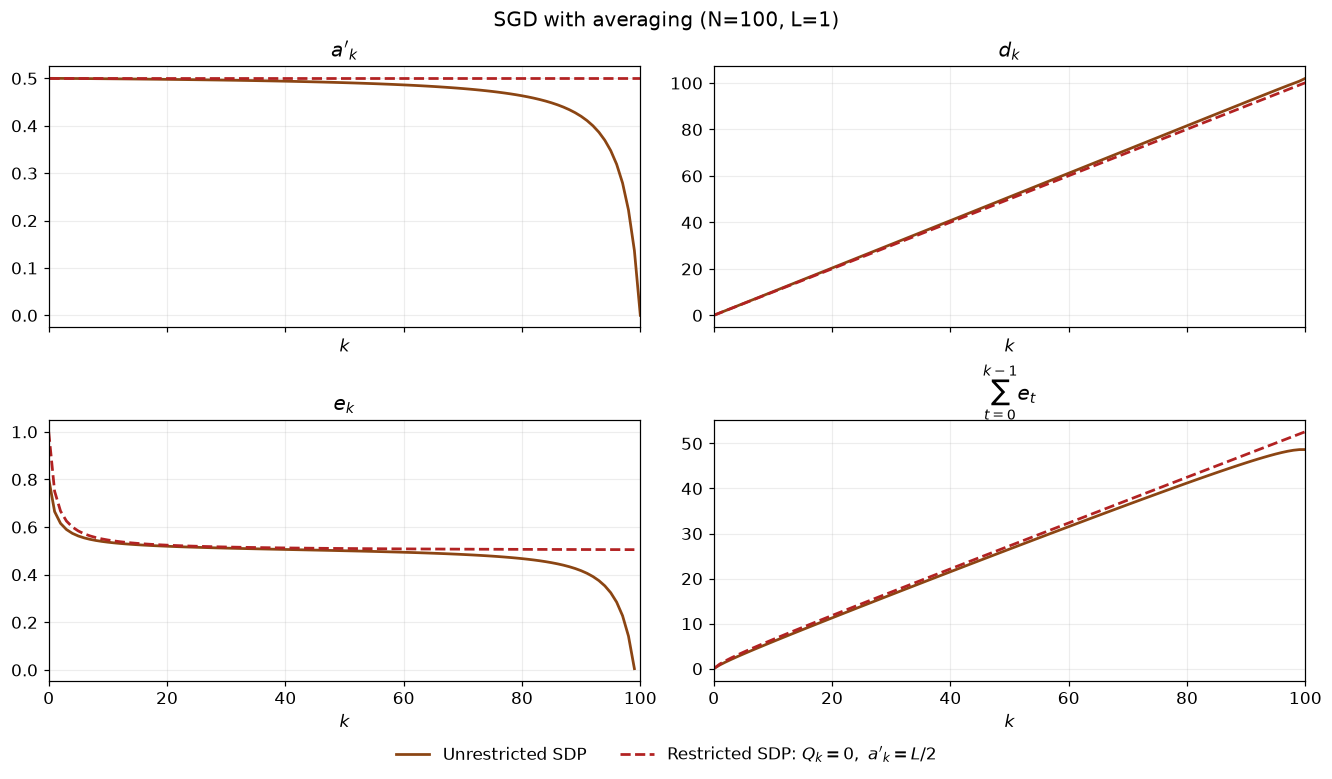

In [13]:
styles_avg = {0: ("Unrestricted SDP", "saddlebrown", "-"),
              1: (r"Restricted SDP: $Q_k=0,\ a'_k=L/2$", "firebrick", "--")}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax, title in zip(("ap", "d", "e", "ec"), axes.flat,
                           (r"$a'_k$", r"$d_k$", r"$e_k$", r"$\sum_{t=0}^{k-1}e_t$")):
    for relax, result in averaging_results.items():
        label, color, linestyle = styles_avg[relax]
        ax.plot(np.arange(len(result[key])), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set(title=title, xlabel=r"$k$",
           xlim=(0, N_FIGURE))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"SGD with averaging (N={N_FIGURE}, L={L:g})")
plt.show()


평균점에 관한 이차항도 따로 살펴본다. $Q_k$의 성분 $a_k,b_k,c_k$는 각각 $z_k$와 최적점 사이의 거리 제곱, gradient norm 제곱, 두 벡터의 내적에 대응한다. 다음 그림은 이 세 계수와 SGD 반복점의 거리항 계수 $a'_k$를 함께 보여 준다.


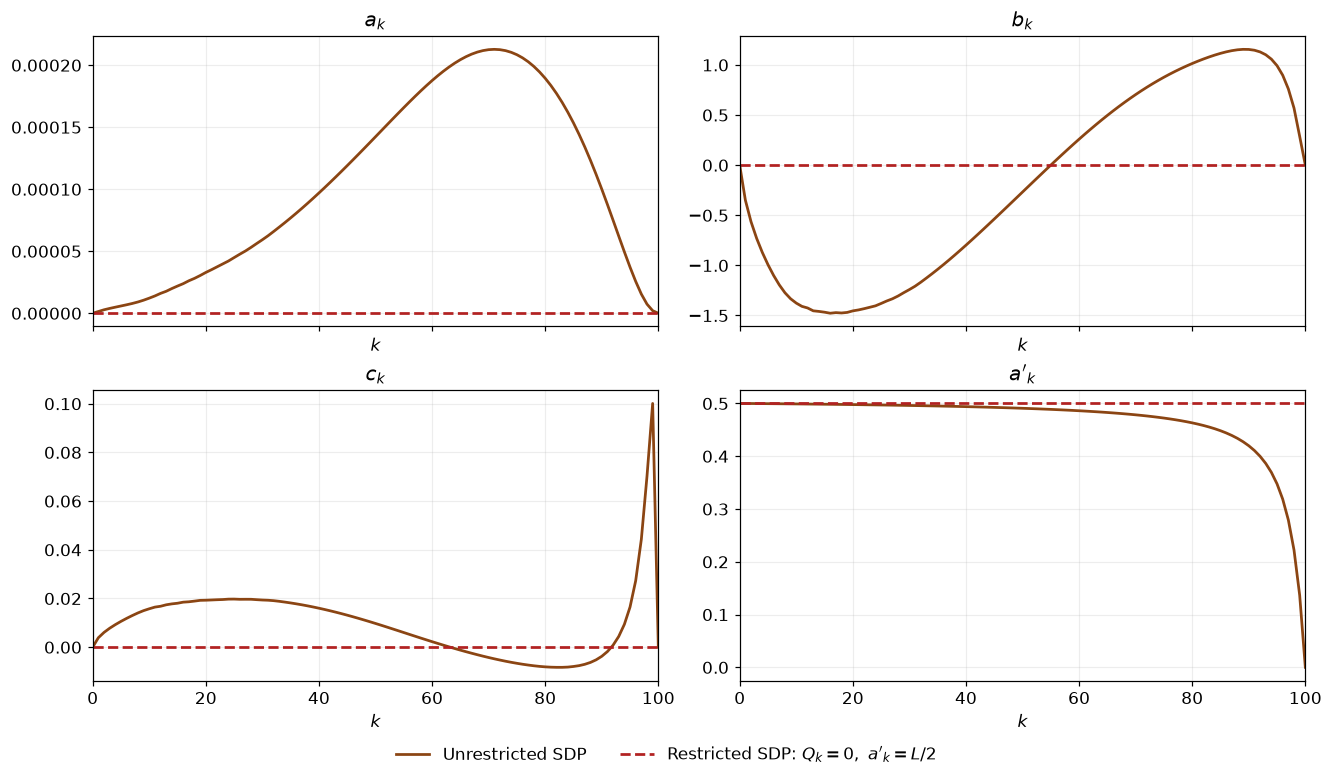

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax, title in zip(("a", "b", "c", "ap"), axes.flat,
                           (r"$a_k$", r"$b_k$", r"$c_k$", r"$a'_k$")):
    for relax, result in averaging_results.items():
        label, color, linestyle = styles_avg[relax]
        ax.plot(np.arange(N_FIGURE + 1), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set(title=title, xlabel=r"$k$", xlim=(0, N_FIGURE))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()


### 5단계 · 해석적 potential inequality와 수렴률

4단계에서 살펴본 제한 potential은 $Q_k=0$, $a'_k=L/2$라는 단순한 구조를 사용한다. 이제 이 구조를 유지하면서 $d_k$와 $e_k$를 명시적으로 선택하고, 한 단계 potential inequality를 증명한다. 수치 수열과의 비교로 계수의 형태를 살펴보고, 이 계수가 모든 단계에서 부등식을 만족한다는 사실은 이어지는 interpolation 부등식의 가중합으로 증명한다.

#### Theorem 6 — 모든 단계에 사용할 명시적 계수

한 단계에서 평균 가중치를 $d_k\ge0$로 두면 알고리즘은

$$x_{k+1}^{(i)}=x_k-\delta_kG(x_k;i),\qquad
z_{k+1}^{(i)}
=\frac{x_{k+1}^{(i)}+d_kz_k}{d_k+1}$$

이다. 여기서 $d_k$는 평균을 만드는 가중치이며, potential의 함수값 계수는 현재 단계에서 $L\delta_kd_k$, 다음 단계에서 $L\delta_k(d_k+1)$이다. Theorem 6은

$$\begin{aligned}
&L\delta_k(d_k+1)\mathbb E_i[f(z_{k+1}^{(i)})-f_\star]
+\frac L2\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2\\
&\qquad\le L\delta_kd_k(f(z_k)-f_\star)
+\frac L2\|x_k-x_\star\|^2+e_k\sigma^2
\end{aligned}$$

를 다음 계수와 step-size 범위에서 보장한다.

$$e_k=\frac{L\delta_k^2}{2}
\left(1+\frac{L\delta_k}{d_k+1}\right),\qquad
0\le\delta_k\le\frac{1+\sqrt5}{2L}.$$

현재 실험처럼 $\delta_k=1/L$, $d_k=k$로 선택하면 각 단계의 함수값 계수가 이어지고,

$$d_k=k,\qquad a'_k=L/2,\qquad Q_k=0,\qquad
e_k=\frac1{2L}\left(1+\frac1{k+1}\right)$$

를 얻는다. 아래에서는 이 명시적 수열을 만들어 수치해와 비교한다.


In [15]:
k = np.arange(N_FIGURE + 1)
transitions = np.arange(N_FIGURE)
analytical_avg = {
    "a": np.zeros(N_FIGURE + 1), "b": np.zeros(N_FIGURE + 1),
    "c": np.zeros(N_FIGURE + 1), "ap": np.full(N_FIGURE + 1, L / 2),
    "d": k.astype(float), "e": (1 + 1 / (transitions + 1)) / (2 * L),
}
analytical_avg["ec"] = np.r_[0., np.cumsum(analytical_avg["e"])]


수치해에서는 단순한 potential에서도 함수값 계수가 비슷하게 증가하는 모습을 볼 수 있었다. 이제 최종 거리항을 유지하는 `relax=1`의 수치해와 Theorem 6의 명시적 수열을 비교한다. 두 수열은 $Q_0,Q_N,a'_0,a'_N$의 경계 조건 형태가 같지만, 최적화로 정한 $d_N$의 값까지 같다고 가정하지는 않는다.


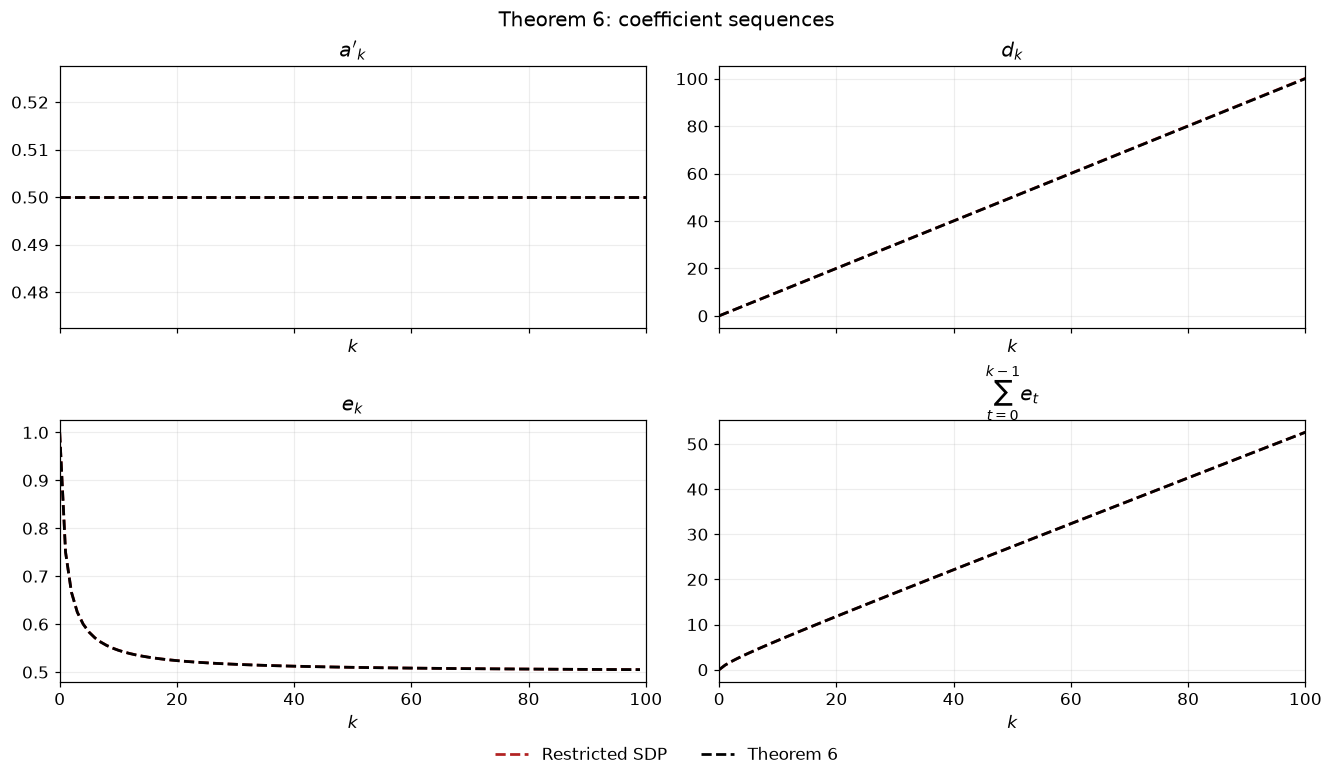

In [16]:
curves_avg = [(averaging_results[1], "Restricted SDP", "firebrick", "--"),
              (analytical_avg, "Theorem 6", "black", "--")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax, title in zip(("ap", "d", "e", "ec"), axes.flat,
                           (r"$a'_k$", r"$d_k$", r"$e_k$", r"$\sum_{t=0}^{k-1}e_t$")):
    for result, label, color, linestyle in curves_avg:
        ax.plot(np.arange(len(result[key])), result[key], label=label, color=color,
                linestyle=linestyle, linewidth=1.8)
    ax.set(title=title, xlabel=r"$k$",
           xlim=(0, N_FIGURE))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Theorem 6: coefficient sequences")
plt.show()


In [17]:
headers = ["계수 수열", r"$d_N$", r"$\sum_{k=0}^{N-1}e_k$", r"$(\sum e_k)/d_N$"]
rows = []
for label, result in (("relax=1 수치해", averaging_results[1]),
                      ("Theorem 6", analytical_avg)):
    d_final = result["d"][-1]
    error_sum = result["ec"][-1]
    rows.append((label, f"{d_final:.8f}", f"{error_sum:.8f}",
                 f"{error_sum / d_final:.8f}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))


| 계수 수열 | $d_N$ | $\sum_{k=0}^{N-1}e_k$ | $(\sum e_k)/d_N$ |
| --- | --- | --- | --- |
| relax=1 수치해 | 100.11846808 | 52.60419013 | 0.52541945 |
| Theorem 6 | 100.00000000 | 52.59368876 | 0.52593689 |

그림의 두 곡선은 가깝지만 동일하지 않다. 수치해는 $d_N\approx100.118468$, $\sum e_k\approx52.604190$이고, 정리의 수열은 $d_N=100$, $\sum e_k\approx52.593689$이다. 오차 계수의 누적합만 보면 정리의 수열이 작지만, $d_N$으로 나눈 분산 계수는 수치해가 조금 작다. 상한의 분모도 함께 달라졌기 때문이다.

Theorem 6은 모든 단계에서 부등식을 만족하는 명시적 수열을 제공한다. 이 수열이 SDP로 구한 수치해와 항마다 일치할 필요는 없다. 다음 증명에서는 함수값 계수와 오차 계수의 이러한 형태가 interpolation 부등식의 가중합에서 어떻게 나오는지 살펴본다.


#### Appendix E.2 — 함수값 항을 소거하고 평균 갱신식을 사용하기

한 단계의 평균 가중치를 $d_k\ge0$로 두고, $\mathbb E_i$는 현재 상태를 고정한 조건부 기대값을 뜻한다. Theorem 6의 현재·다음 함수값 계수는 각각 $L\delta_kd_k$, $L\delta_k(d_k+1)$이다. 먼저 **각각 0 이하인 항**들을 다음과 같이 합한다.

$$\begin{aligned}
0\ge{}&
-L\delta_k\left[f_\star-f(x_k)-\langle f'(x_k),x_\star-x_k\rangle-\frac1{2L}\Vert f'(x_k)\Vert^2\right]
-L\delta_k\mathbb E_i\left[f(x_k)-f(z_{k+1}^{(i)})-\langle f'(z_{k+1}^{(i)}),x_k-z_{k+1}^{(i)}\rangle-\frac1{2L}\Vert f'(x_k)-f'(z_{k+1}^{(i)})\Vert^2\right]\\
&-L\delta_kd_k\mathbb E_i\left[f(z_k)-f(z_{k+1}^{(i)})-\langle f'(z_{k+1}^{(i)}),z_k-z_{k+1}^{(i)}\rangle-\frac1{2L}\Vert f'(z_k)-f'(z_{k+1}^{(i)})\Vert^2\right]
+e_k\left(
\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2-\sigma^2
\right).
\end{aligned}$$

함수값 항만 모으면

$$\begin{aligned}
&L\delta_k(f(x_k)-f_\star)
+L\delta_k\mathbb E_i[f(z_{k+1}^{(i)})-f(x_k)]\\
&\qquad+L\delta_kd_k\mathbb E_i[f(z_{k+1}^{(i)})-f(z_k)]\\
&=L\delta_k(d_k+1)\mathbb E_i[f(z_{k+1}^{(i)})-f_\star]
-L\delta_kd_k(f(z_k)-f_\star).
\end{aligned}$$

중간 함수값 $f(x_k)$가 소거되어, 원하는 potential 차이의 함수값 부분이 남는다. 다음으로 두 번째와 세 번째 interpolation 부등식의 내적항을 묶는다. 평균 갱신식과 SGD 갱신식에 의해

$$x_k+d_kz_k-(d_k+1)z_{k+1}^{(i)}
=x_k-x_{k+1}^{(i)}=\delta_kG(x_k;i)$$

이므로

$$\begin{aligned}
&L\delta_k\mathbb E_i
\langle f'(z_{k+1}^{(i)}),x_k-z_{k+1}^{(i)}\rangle\\
&\quad+L\delta_kd_k\mathbb E_i
\langle f'(z_{k+1}^{(i)}),z_k-z_{k+1}^{(i)}\rangle\\
&=L\delta_k^2\mathbb E_i
\langle f'(z_{k+1}^{(i)}),G(x_k;i)\rangle.
\end{aligned}$$

첫 번째 interpolation 부등식의 내적항은 SGD 반복점의 거리항과 연결된다. Unbiasedness를 사용하면

$$\begin{aligned}
&\frac L2\left(
\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2-\|x_k-x_\star\|^2
\right)\\
&=-L\delta_k\langle f'(x_k),x_k-x_\star\rangle
+\frac{L\delta_k^2}{2}\mathbb E_i\|G(x_k;i)\|^2.
\end{aligned}$$

따라서 처음의 가중합을 항별로 정리하면

$$\begin{aligned}
0\ge{}&L\delta_k(d_k+1)\mathbb E_i[f(z_{k+1}^{(i)})-f_\star]
+\frac L2\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2
-L\delta_kd_k(f(z_k)-f_\star)-\frac L2\|x_k-x_\star\|^2\\
&-e_k\sigma^2\\
&+\frac{\delta_k}{2}\|f'(x_k)\|^2
+\frac{\delta_k}{2}\mathbb E_i
\|f'(x_k)-f'(z_{k+1}^{(i)})\|^2\\
&+\frac{d_k\delta_k}{2}\mathbb E_i
\|f'(z_k)-f'(z_{k+1}^{(i)})\|^2\\
&+L\delta_k^2\mathbb E_i
\langle f'(z_{k+1}^{(i)}),G(x_k;i)\rangle\\
&+\left(e_k-\frac{L\delta_k^2}{2}\right)
\mathbb E_i\|G(x_k;i)\|^2
-e_k\|f'(x_k)\|^2
\end{aligned}$$

이다. 마지막 줄에서는 unbiasedness로부터 얻는
$\mathbb E_i\|G(x_k;i)-f'(x_k)\|^2
=\mathbb E_i\|G(x_k;i)\|^2-\|f'(x_k)\|^2$를 사용했다.


#### Appendix E.2 — 오차 계수를 선택하고 완전제곱으로 정리하기

이제 앞 식에서 함수값·거리항 차이와 $-e_k\sigma^2$ 뒤에 남은 이차항들의 합이 비음수임을 보이면 된다. 먼저 $f'(z_{k+1}^{(i)})$를 포함하는 항을 모아 완전제곱식으로 정리한다.

$$\begin{aligned}
&\frac{(d_k+1)\delta_k}{2}\mathbb E_i
\|f'(z_{k+1}^{(i)})\|^2\\
&\quad-\delta_k\mathbb E_i
\langle f'(z_{k+1}^{(i)}),
d_kf'(z_k)+f'(x_k)-L\delta_kG(x_k;i)\rangle\\
&=\frac{(d_k+1)\delta_k}{2}\mathbb E_i
\left\|f'(z_{k+1}^{(i)})
-\frac{d_kf'(z_k)+f'(x_k)-L\delta_kG(x_k;i)}
{d_k+1}\right\|^2\\
&\quad-\frac{\delta_k}{2(d_k+1)}\mathbb E_i
\|d_kf'(z_k)+f'(x_k)-L\delta_kG(x_k;i)\|^2.
\end{aligned}$$

마지막에 생긴 제곱항에는 음의 계수가 붙는다. 이 항에서 $\mathbb E_i\|G(x_k;i)\|^2$의 계수는
$-L^2\delta_k^3/[2(d_k+1)]$이다. 따라서

$$e_k=\frac{L\delta_k^2}{2}
\left(1+\frac{L\delta_k}{d_k+1}\right),\qquad
e_k-\frac{L\delta_k^2}{2}
=\frac{L^2\delta_k^3}{2(d_k+1)}$$

로 선택하면 oracle 출력의 norm 제곱항이 정확히 소거된다. 이것이 Theorem 6의 오차 계수에 추가항이 들어가는 이유다. Oracle 출력을 포함하는 나머지 내적항에는 $\mathbb E_iG(x_k;i)=f'(x_k)$를 사용한다.

첫 번째 완전제곱 바깥의 항도 다시 제곱으로 묶을 수 있다.

$$\begin{aligned}
&\frac{d_k\delta_k}{2(d_k+1)}\|f'(z_k)\|^2
+\frac{d_k\delta_k(L\delta_k-1)}{d_k+1}
\langle f'(z_k),f'(x_k)\rangle\\
&\quad+\frac{\delta_k}{2}
\left[2-L\delta_k-\frac{(L\delta_k-1)^2}{d_k+1}\right]
\|f'(x_k)\|^2\\
&=\frac{d_k\delta_k}{2(d_k+1)}
\|f'(z_k)+(L\delta_k-1)f'(x_k)\|^2\\
&\quad+\frac{\delta_k}{2}
\bigl[1+L\delta_k-(L\delta_k)^2\bigr]\|f'(x_k)\|^2.
\end{aligned}$$

따라서 남은 이차항들은 첫 번째 완전제곱과 방금 얻은 두 항의 합이다. $d_k,\delta_k\ge0$이면 두 완전제곱 앞의 계수는 비음수다. 마지막 gradient norm 제곱항의 부호는

$$1+L\delta_k-(L\delta_k)^2\ge0
\quad\Longleftrightarrow\quad
0\le\delta_k\le\frac{1+\sqrt5}{2L}$$

로 결정된다. 이 범위에서 위 세 이차항이 모두 비음수이므로, Theorem 6의 다음 단계 함수값·거리항 합은 현재 단계 함수값·거리항 합에 $e_k\sigma^2$를 더한 값 이하다. 황금비 형태의 step-size 상한은 이 마지막 이차항이 비음수가 되도록 요구한 결과다.


#### 고정 step-size에서 함수값 상한으로 연결하기

$\delta_k=1/L$, $d_k=k$이면
$z_N=N^{-1}\sum_{t=1}^Nx_t$이다. 한 단계 부등식에 전체 기대값을 취해 더하면

$$N\mathbb E[f(z_N)-f_\star]
+\frac L2\mathbb E\|x_N-x_\star\|^2
\le\frac L2\|x_0-x_\star\|^2+\frac{N+\sum_{j=1}^N\frac1j}{2L}\sigma^2$$

를 얻는다. 따라서

$$\boxed{\mathbb E[f(z_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2N}
+\frac{\sigma^2}{2L}\left(1+\frac{\sum_{j=1}^N\frac1j}{N}\right).}$$

SGD에서 $O(N)$으로 증가하던 분산 계수는 이 평균법에서 $1/(2L)$로 수렴한다. 여기에 더해지는 항은 $\sum_{j=1}^N\frac1j/(2LN)$이다. 먼저 증명에서 얻은 완전제곱 표현을 Gram 행렬에 대한 부등식으로 바꾸어 보고, 이어서 oracle 평가점을 바꾸면 이 추가항도 없앨 수 있는지 살펴본다.


#### 증명의 multiplier와 행렬 부등식

Theorem 6의 평균 가중치 $d_k=k$, $\delta_k=1/L$에서는

$$\lambda_{\star,x_k}=1,\qquad
\lambda_{x_k,z_{k+1}^{(i)}}=1/n,\qquad
\lambda_{z_k,z_{k+1}^{(i)}}=k/n$$

이고 나머지는 0이다. 기대값으로 묶인 가중치를 outcome별로 나누므로 $1/n$이 붙는다. 원본 2B의 계수벡터로 쓰면 남은 행렬은

$$\begin{aligned}
&\frac1n\sum_iV_{k+1}^{(i)}-V_k-e_kA_{\rm var}+\sum_{i\ne j}\lambda_{i,j}M_{i,j}\\
&=-\frac{k+1}{2Ln}\sum_i
\left(\mathtt{gzk1}[i-1]-\frac{\mathtt{gxk}+k\mathtt{gzk}-\mathtt{Gxk}[i-1]}{k+1}\right)
\left(\mathtt{gzk1}[i-1]-\frac{\mathtt{gxk}+k\mathtt{gzk}-\mathtt{Gxk}[i-1]}{k+1}\right)^\top\\
&\quad-\frac{k}{2L(k+1)}\mathtt{gzk}\mathtt{gzk}^\top
-\frac1{2L}\mathtt{gxk}\mathtt{gxk}^\top\preceq0.
\end{aligned}$$

함수값 계수는 모두 소거된다. 각 outer product는 양의 준정부호이고 앞의 계수는 0 이하이므로 LMI가 성립한다. 아래 코드는 이 계수와 multiplier를 원래 행렬 부등식에 대입한다.


In [18]:
weights_avg = np.zeros((N_FIGURE, nbPts, nbPts))
matrices_avg, equalities_avg, expected_avg = [], [], []
for k in range(1, N_FIGURE + 1):
    weights = weights_avg[k - 1]
    weights[0, 1] = 1
    for i in range(1, n + 1):
        weights[1, 2 + i] = 1 / n
        weights[2, 2 + i] = (k - 1) / n
    XK1, ZK1 = xk1(k), zk1(k)
    matrix = -L / 2 * np.outer(xk, xk) - analytical_avg["e"][k - 1] * Avar
    equality = -(k - 1) * fzk
    X, G, F = {1: xs, 2: xk, 3: zk}, {1: gxs, 2: gxk, 3: gzk}, {1: fxs, 2: fxk, 3: fzk}
    for i in range(1, n + 1):
        matrix = matrix + L / (2 * n) * np.outer(XK1[i - 1], XK1[i - 1])
        equality = equality + k / n * fzk1[i - 1]
        X[3 + i], G[3 + i], F[3 + i] = ZK1[i - 1], gzk1[i - 1], fzk1[i - 1]
    for i in range(1, nbPts + 1):
        for j in range(1, nbPts + 1):
            if i != j:
                TT = np.vstack((X[i], X[j], G[i], G[j]))
                matrix = matrix + weights[i - 1, j - 1] * (TT.T @ M @ TT)
                equality = equality + weights[i - 1, j - 1] * (F[i] - F[j])
    w = gzk1 - (gxk + (k - 1) * gzk - Gxk) / k
    expected = -k / (2 * L * n) * (w.T @ w)
    expected = expected - (k - 1) / (2 * L * k) * np.outer(gzk, gzk) - np.outer(gxk, gxk) / (2 * L)
    matrices_avg.append(matrix)
    equalities_avg.append(equality)
    expected_avg.append(expected)


In [19]:
matrices_avg = np.asarray(matrices_avg)
equalities_avg = np.asarray(equalities_avg)
expected_avg = np.asarray(expected_avg)
check_avg = {
    "R": matrices_avg, "equality": equalities_avg,
    "lmi_violation": max(0., float(np.linalg.eigvalsh(matrices_avg).max())),
    "equality_violation": float(np.abs(equalities_avg).max()),
    "multiplier_violation": max(0., float(-weights_avg.min())),
    "identity_error": float(np.abs(matrices_avg - expected_avg).max()),
}

print(f"Theorem 6: matrix identity error={check_avg['identity_error']:.3e}")


Theorem 6: matrix identity error=7.105e-15


## B. Primal averaging

### 1단계 · 알고리즘과 가정

고정 step-size $\delta_k=1/L$에서 Theorem 6의 $e_k=\frac{1}{2L}(1+1/(k+1))$에는 추가항 $1/[2L(k+1)]$이 남는다. Primal averaging에서는 oracle 평가점을 $x_k$에서 $y_{k+1}$로 변경하며, $f\in\mathcal F_L$ 및 조건부 불편성·분산 상한은 그대로 유지한다.

SGD with averaging에서 $z_{k+1}^{(i)}$는 현재 oracle 결과에 의존한다. Primal averaging의 $y_{k+1}$은 oracle 호출 전에 정해진다. 이 차이가 $e_k$의 추가항을 제거하는지 Theorem 7에서 확인한다.

$$d_{k+1}=d_k+L\delta_k,\qquad
y_{k+1}=\frac{d_ky_k+L\delta_kx_k}{d_{k+1}},\qquad
x_{k+1}^{(i)}=x_k-\delta_kG(y_{k+1};i).$$

$\delta_k=1/L$, $d_0=0$이면 $d_k=k$이다. $y_{k+1}$은 현재 oracle 호출 전에 정해지므로, oracle 결과마다 서로 다른 다음 평균점과 gradient를 둘 필요가 없다. $n=2$일 때 앞의 $7\times7$ Gram 표현이 여기서 $5\times5$로 줄어드는 이유도 이 차이에 있다.


In [20]:
N = N_FIGURE
alpha = 0
delta = lambda k: 1 / L / (k + 1) ** alpha

### 2단계 · Parameterized potential 설정

1단계에서 평균점 $y_{k+1}$을 먼저 계산하도록 알고리즘을 바꾸었다. 따라서 A의 potential에서 평균점의 역할을 $z_k$ 대신 $y_k$가 맡는다. 함수값 계수 $d_k$는 이번 알고리즘의 평균 가중치에도 들어가므로, 점화식으로 미리 정한 뒤 다른 potential 계수와 오차 계수를 탐색한다.

이번에는 함수값과 평균점의 이차항을 $y_k$에서 평가한다.

$$\phi_k^f=
\begin{pmatrix}y_k-x_\star\\ f'(y_k)\end{pmatrix}^{\!\top}
(Q_k\otimes I)
\begin{pmatrix}y_k-x_\star\\ f'(y_k)\end{pmatrix}
+d_k(f(y_k)-f_\star)+a'_k\|x_k-x_\star\|^2.$$

두 설정 모두 $Q_0=Q_N=0$, $d_0=0$, $a'_0=L/2$이며, $\phi_N^f$는 다음과 같다.

| `relax` | 중간 계수 ($0<k<N$) | $\phi_0^f$ | $\phi_N^f$ |
| --- | --- | --- | --- |
| 0 | $Q_k\in\mathbb S^2$, $a'_k$ 자유 | $\frac L2\|x_0-x_\star\|^2$ | $d_N(f(y_N)-f_\star)$ |
| 1 | $Q_k=0$, $a'_k=L/2$ | $\frac L2\|x_0-x_\star\|^2$ | $d_N(f(y_N)-f_\star)+\frac L2\|x_N-x_\star\|^2$ |

이번에는 두 설정 모두 $d_k$를 알고리즘의 점화식 $d_{k+1}=d_k+L\delta_k$로 먼저 고정한다. 따라서 각 설정에서 함수값 계수를 고정한 채 $\sum_{k=0}^{N-1}e_k$를 최소화하는 SDP를 한 번 푼다. 원본 코드의 딕셔너리 인덱스를 유지하므로, 수식의 상태 $k$는 `Q[k+1]`, `d[k+1]`, `ap[k+1]`에 대응한다.


In [21]:
primal_models = {}
for relax in (0, 1):
    a0 = b0 = c0 = d0 = 0
    ap0 = L / 2
    aN = bN = cN = 0
    apN = 0 if relax == 0 else L / 2
    Q0 = np.array([[a0, c0], [c0, b0]])
    QN = np.array([[aN, cN], [cN, bN]])
    primal_models[relax] = {
        "Q": {1: Q0, N + 1: QN}, "d": {1: d0},
        "ap": {1: ap0, N + 1: apN}, "lam": {}, "e": {},
        "cons_SDP": {}, "cons_LIN": {}, "cons": [],
    }

2단계에서 정한 상태별 potential 계수를 선언한 뒤, 다음 단계의 LMI에 필요한 업데이트마다 사용할 multiplier도 준비한다. interpolation 부등식을 적용하는 세 점에 대한 multiplier는 원본 변수 `lam[k]`의 3×3 배열로 저장하며, 분산 조건에는 $e_k\ge0$인 multiplier를 둔다. 같은 점을 두 번 고르는 interpolation 부등식은 항상 $0$이므로 제약을 구성할 때 제외한다.


In [22]:
nbPts = 3
for relax, model in primal_models.items():
    Q, d, ap = model["Q"], model["d"], model["ap"]
    lam, e = model["lam"], model["e"]
    for k in range(1, N + 1):
        if k < N:
            if relax == 0:
                ap[k + 1] = cp.Variable(name=f"ap_{k + 1}")
                Q[k + 1] = cp.Variable((2, 2), symmetric=True, name=f"Q_{k + 1}")
            elif relax == 1:
                ap[k + 1] = L / 2
                Q[k + 1] = np.zeros((2, 2))
        d[k + 1] = d[k] + delta(k) * L
        lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")
        e[k] = cp.Variable(name=f"e_{k}")

### 3단계 · LMI/SDP로 계수 수치 탐색

2단계에서 고정한 $d_k$와 potential을 한 단계 LMI로 옮긴다. 이후에는 $\sum e_k$를 한 번 최소화한다. 평균점은 현재 oracle 결과에 의존하지 않으므로 Gram 행렬의 크기가 작아진다.

#### 한 단계의 Gram 표현

$x_\star=f_\star=0$으로 옮기고 원본 2C 코드대로

$$P=[x_k\quad y_k\quad f'(y_k)\quad G(y_{k+1};1)\ \cdots\ G(y_{k+1};n)],
\qquad F=[f(y_k),f(y_{k+1})]$$

를 사용한다. $F$는 논문과 같은 행벡터다. Unbiasedness에 의해

$$f'(y_{k+1})=\frac1n\sum_iG(y_{k+1};i)$$

이고 코드의 `gyk1`이 이 gradient의 계수벡터다. $G=P^\top P$는 $(3+n)$×$(3+n)$이며, $n=2$이면 5×5다.


In [23]:
dimG, dimF = 3 + n, 2
xk = np.zeros(dimG)
xk[0] = 1
yk = np.zeros(dimG)
yk[1] = 1
xs = np.zeros(dimG)
gyk = np.zeros(dimG)
gyk[2] = 1
Gyk1 = np.zeros((n, dimG))
Gyk1[:, 3:n + 3] = np.eye(n)
gyk1 = np.sum(Gyk1, axis=0) / n
gxs = np.zeros(dimG)
fyk = np.zeros(dimF)
fyk[0] = 1
fyk1 = np.zeros(dimF)
fyk1[1] = 1
fxs = np.zeros(dimF)

다음 평균점은 oracle 호출 전에 정해진다.

$$y_{k+1}=\frac{L\delta_kx_k+d_ky_k}{d_k+L\delta_k},\qquad
x_{k+1}^{(i)}=x_k-\delta_kG(y_{k+1};i).$$

아래 코드의 `yk1(d[k], k)`, `xk1(k)[i-1]`은 이 점들을 나타내는 원본 계수벡터다. 다음 potential의 $y_{k+1}$ 항은 모든 outcome에서 같고, $x_{k+1}^{(i)}$의 거리항에는 outcome에 대한 평균이 필요하다.


In [24]:
yk1 = lambda dk, k: delta(k) * L / (dk + delta(k) * L) * xk + dk / (dk + delta(k) * L) * yk
xk1 = lambda k: np.ones((n, 1)) * xk - delta(k) * Gyk1
statesKG = np.column_stack((yk - xs, gyk))
statesKF = fyk
statesK1F = fyk1

논문의 interpolation 행렬은 원본 코드의 `TT`로 직접 계산한다.

$$M_{i,j}=\mathtt{TT}^{\top}M\mathtt{TT},\qquad
A_{\rm var}=\frac1n\sum_i
(\mathtt{Gyk1}[i-1]-\mathtt{gyk1})(\mathtt{Gyk1}[i-1]-\mathtt{gyk1})^\top.$$

`TT = np.vstack((X[i], X[j], G[i], G[j]))`이며, interpolation point는 $\{x_\star,y_k,y_{k+1}\}$의 세 개다. 분산 행렬에는 oracle 평가점 $y_{k+1}$의 gradient를 사용한다.


In [25]:
M = np.array([
    [-L * m, L * m, m, -L],
    [L * m, -L * m, -m, L],
    [m, -m, -1, 1],
    [-L, L, 1, -1],
]) / (2 * (L - m))
Avar = np.zeros((dimG, dimG))
for i in range(1, n + 1):
    Avar = Avar + np.outer(Gyk1[i - 1] - gyk1, Gyk1[i - 1] - gyk1) / n

#### Potential 차이와 분산 항을 구성하기

논문의 $V_k,V_{k+1}^{(i)}$는 원본 2C의 `statesKG`, `statesK1G`, `XK1`로 구성한다.

$$V_k=\mathtt{statesKG}\,Q_k\mathtt{statesKG}^{\top}
+a'_k(\mathtt{xk}-\mathtt{xs})(\mathtt{xk}-\mathtt{xs})^\top,$$
$$V_{k+1}^{(i)}=\mathtt{statesK1G}\,Q_{k+1}\mathtt{statesK1G}^{\top}
+a'_{k+1}(\mathtt{XK1}[i-1]-\mathtt{xs})(\mathtt{XK1}[i-1]-\mathtt{xs})^\top.$$

다음 평균점에 관한 첫 항은 outcome에 공통이다. 아래에서는

$$\frac1n\sum_iV_{k+1}^{(i)}-V_k-e_kA_{\rm var},\qquad
-d_k\mathtt{fyk}+d_{k+1}\mathtt{fyk1}$$

를 원본의 `cons_SDP[k]`, `cons_LIN[k]`에 구성한다. 다음 SGD 반복점의 거리항에는 oracle 결과의 평균이 남는다.


In [26]:
for model in primal_models.values():
    Q, d, ap, e = model["Q"], model["d"], model["ap"], model["e"]
    cons_SDP, cons_LIN = model["cons_SDP"], model["cons_LIN"]
    for k in range(1, N + 1):
        XK1 = xk1(k)
        cons_SDP[k] = -statesKG @ Q[k] @ statesKG.T - ap[k] * np.outer(xk - xs, xk - xs) - e[k] * Avar
        cons_LIN[k] = -d[k] * statesKF
        statesK1G = np.column_stack((yk1(d[k], k) - xs, gyk1))
        cons_SDP[k] = cons_SDP[k] + statesK1G @ Q[k + 1] @ statesK1G.T
        for i in range(1, n + 1):
            cons_SDP[k] = cons_SDP[k] + ap[k + 1] * np.outer(XK1[i - 1] - xs, XK1[i - 1] - xs) / n
        cons_LIN[k] = cons_LIN[k] + statesK1F * d[k + 1]

서로 다른 두 점의 모든 순서쌍에 multiplier를 곱해 더한다.

$$\frac1n\sum_iV_{k+1}^{(i)}-V_k-e_kA_{\rm var}
+\sum_{i\ne j}\lambda_{i,j}M_{i,j}\preceq0,$$
$$-d_k\mathtt{fyk}+d_{k+1}\mathtt{fyk1}
+\sum_{i\ne j}\lambda_{i,j}(\mathtt{F}[i]-\mathtt{F}[j])=0.$$

두 번째 식으로 함수값 계수를 소거한다. 첫 번째 식은 모든 Gram 행렬 $G\succeq0$에서 남은 이차항이 0 이하가 되도록 한다.


In [27]:
for model in primal_models.values():
    d, lam = model["d"], model["lam"]
    cons_SDP, cons_LIN = model["cons_SDP"], model["cons_LIN"]
    for k in range(1, N + 1):
        X = {1: xs, 2: yk, 3: yk1(d[k], k)}
        G = {1: gxs, 2: gyk, 3: gyk1}
        F = {1: fxs, 2: fyk, 3: fyk1}
        for i in range(1, nbPts + 1):
            for j in range(1, nbPts + 1):
                if j != i:
                    xi, xj = X[i], X[j]
                    gi, gj = G[i], G[j]
                    fi, fj = F[i], F[j]
                    TT = np.vstack((xi, xj, gi, gj))
                    cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * (TT.T @ M @ TT)
                    cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * (fi - fj)

#### 함수값 계수를 고정하고 오차 계수의 누적합을 최소화하기

$d_{k+1}=d_k+L\delta_k$를 미리 정하고 $\min\sum_{k=0}^{N-1}e_k$를 푼다. 제약은 바로 위의 행렬 부등식과 함수값 계수 등식, $\lambda_{i,j}\ge0$, $e_k\ge0$이다.

원본 변수로는 `cons_SDP[k] << 0`, `cons_LIN[k] == 0`, `lam[k] >= 0`, `e[k] >= 0`을 부과한다. `lam[k] >= 0`은 각 multiplier가 비음수라는 뜻이다.


In [28]:
for relax, model in primal_models.items():
    cons, e, lam = model["cons"], model["e"], model["lam"]
    for k in range(1, N + 1):
        cons = cons + [model["cons_SDP"][k] << 0]
        cons = cons + [model["cons_LIN"][k] == 0]
        cons = cons + [lam[k] >= 0]
        cons = cons + [e[k] >= 0]
    accumulated_ek = 0
    for k in range(1, N + 1):
        accumulated_ek = accumulated_ek + e[k]
    solver_opt = {"solver": solver, "verbose": bool(verbose),
                  "mosek_params": {"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance}}
    problem = cp.Problem(cp.Minimize(accumulated_ek), cons)
    started = perf_counter()
    solve(problem, ** solver_opt)
    model.update(problem=problem, cons=cons, seconds=perf_counter() - started)
    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"primal relax={relax}: {problem.status}")


최적화가 끝나면 $Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$에서 세 계수를 추출한다. $a'_k,d_k$와 함께 수식의 상태 순서 $k=0,\ldots,N$에 맞춰 배열에 저장하고, 각 업데이트의 오차 계수 $e_k$로부터 누적합 $\sum_{t=0}^{k-1}e_t$도 계산한다.


In [29]:
primal_results = {}
for relax, model in primal_models.items():
    Q, d, ap, e = model["Q"], model["d"], model["ap"], model["e"]
    Q_values = np.stack([Q[k].value if isinstance(Q[k], cp.Expression) else Q[k]
                         for k in range(1, N + 2)])
    ap_values = np.array([float(ap[k].value if isinstance(ap[k], cp.Expression) else ap[k])
                          for k in range(1, N + 2)])
    e_values = np.array([float(e[k].value) for k in range(1, N + 1)])
    primal_results[relax] = {
        "a": Q_values[:, 0, 0], "b": Q_values[:, 1, 1], "c": Q_values[:, 1, 0],
        "d": np.array([d[k] for k in range(1, N + 2)]), "ap": ap_values,
        "e": e_values, "ec": np.r_[0., np.cumsum(e_values)],
        "multipliers": np.stack([model["lam"][k].value for k in range(1, N + 1)]),
        "R": np.stack([model["cons_SDP"][k].value for k in range(1, N + 1)]),
        "equality": np.stack([model["cons_LIN"][k].value for k in range(1, N + 1)]),
        "d_N": float(d[N + 1]), "sum_e": float(np.sum(e_values)),
        "status": model["problem"].status, "seconds": model["seconds"],
    }
for result in primal_results.values():
    result["residuals"] = {
        "lmi_violation": float(max(0., np.linalg.eigvalsh(result["R"]).max())),
        "equality_violation": float(np.abs(result["equality"]).max()),
        "multiplier_violation": float(max(0., -result["multipliers"].min())),
        "variance_multiplier_violation": float(max(0., -result["e"].min())),
    }


### 4단계 · 계수 패턴 관찰과 단순화

3단계에서는 두 설정에 같은 $d_k$를 사용하고 각각 오차 계수의 누적합을 최소화했다. 이제 계수 수열을 비교해 $e_k$가 거의 일정한지, 최종 거리항을 제거하면 마지막 몇 단계의 계수가 어떻게 달라지는지 살펴본다.

#### 경계조건 $a'_N$에 따른 $e_k$의 변화

아래 그림은 두 설정의 $a'_k$, $d_k$, $e_k$, $\sum_{t<k}e_t$를 비교한다. 함수값 계수 $d_k$는 두 설정에서 같으므로, 최종 거리항을 유지하는지에 따라 오차 계수가 어떻게 달라지는지에 주목하자. 표에는 마지막 업데이트의 $e_{N-1}$과 최종 상한의 분산 계수 $(\sum e_k)/d_N$도 함께 표시한다.


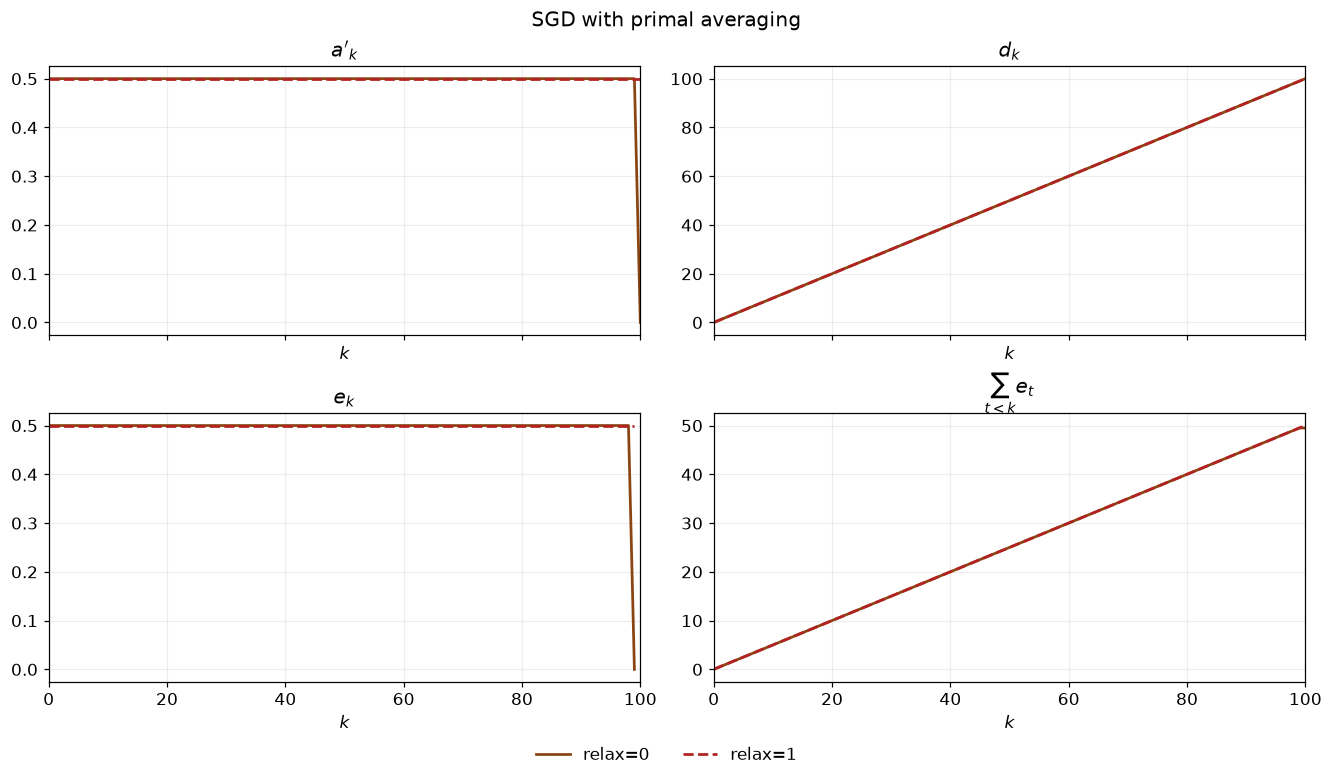

| 설정 | $d_N$ | $a'_N$ | $e_{N-1}$ | $\sum_{k=0}^{N-1}e_k$ | $(\sum e_k)/d_N$ |
| --- | --- | --- | --- | --- | --- |
| 0 | 100 | 0 | 1.35695e-07 | 49.5 | 0.495 |
| 1 | 100 | 0.5 | 0.5 | 50 | 0.5 |

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for relax, color, linestyle in ((0, "saddlebrown", "-"), (1, "firebrick", "--")):
    result = primal_results[relax]
    for ax, key, title in zip(axes.flat, ("ap", "d", "e", "ec"),
                               (r"$a'_k$", r"$d_k$", r"$e_k$", r"$\sum_{t<k}e_t$")):
        iterations = np.arange(N) if key == "e" else np.arange(N + 1)
        ax.plot(iterations, result[key], color=color, linestyle=linestyle,
                linewidth=1.8, label=f"relax={relax}")
        ax.set(title=title, xlim=(0, N), xlabel=r"$k$")
fig.suptitle("SGD with primal averaging")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()
headers = ["설정", r"$d_N$", r"$a'_N$", r"$e_{N-1}$", r"$\sum_{k=0}^{N-1}e_k$", r"$(\sum e_k)/d_N$"]
rows = [[relax, f"{r['d_N']:.6g}", f"{r['ap'][-1]:.6g}", f"{r['e'][-1]:.6g}",
         f"{r['sum_e']:.6g}", f"{r['sum_e'] / r['d_N']:.6g}"]
        for relax, r in primal_results.items()]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines = lines + ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

`relax=0`에서는 $a'_N=0$이고, 마지막 오차 계수 $e_{N-1}$도 수치적으로 거의 $0$이다. $y_N$은 마지막 oracle 호출 전에 정해진다. 따라서 $\phi_N^f=d_N(f(y_N)-f_\star)$이면 마지막 확률적 갱신의 오차가 $\phi_N^f$에 반영되지 않는다.

반면 `relax=1`은 $a'_N=L/2$를 유지하므로 마지막 갱신의 분산이 거리항에 들어간다. 그 결과 $e_{N-1}\approx1/(2L)=0.5$가 남는다. 마지막 오차 계수의 차이는 이렇게 두 설정의 최종 potential 차이와 연결된다.

다음 정리는 거리항을 유지하는 `relax=1`과 같은 형태의 potential에 대해, 모든 단계에서 사용할 계수를 명시적으로 제시한다.


### 5단계 · 해석적 potential inequality와 수렴률

4단계에서 최종 거리항을 유지한 설정의 수치해를 보면, 오차 계수가 거의 일정했다. 이제 그 패턴을 $e_k=L\delta_k^2/2$라는 명시적 식으로 쓰고, 평균 갱신식이 왜 추가항 없이 potential inequality를 성립시키는지 증명한다.

#### Theorem 7의 명시적 계수

Theorem 7은 $0\le\delta_k\le1/L$에서

$$\phi_k^f=d_k(f(y_k)-f_\star)+\frac L2\|x_k-x_\star\|^2,\qquad
d_{k+1}=d_k+L\delta_k,\qquad e_k=\frac{L\delta_k^2}{2}$$

로 두면 $\mathbb E_i\phi_{k+1}^f\le\phi_k^f+e_k\sigma^2$가 성립함을 보장한다. 현재의 $\delta_k=1/L$, $d_0=0$에서는

$$d_k=k,\qquad e_k=\frac1{2L},\qquad
\sum_{k=0}^{N-1}e_k=\frac N{2L}$$

이다. 함수값 계수는 선형으로 증가하고, 단계별 오차 계수는 처음부터 일정하다.


In [31]:
analytical_primal = {
    "a": np.zeros(N + 1), "b": np.zeros(N + 1), "c": np.zeros(N + 1),
    "ap": np.full(N + 1, L / 2), "d": np.arange(N + 1, dtype=float),
    "e": np.full(N, 1 / (2 * L)),
}
analytical_primal["ec"] = np.r_[0., np.cumsum(analytical_primal["e"])]

최종 거리항을 동일하게 유지하는 `relax=1`의 수치 수열과 Theorem 7의 수열을 비교한다. Theorem 6의 $e_k$에 있던 추가항 $1/[2L(k+1)]$가 이번에는 없다. 아래 그림과 표에서 수치해의 오차 계수가 이 일정한 값과 얼마나 가까운지 확인한다.


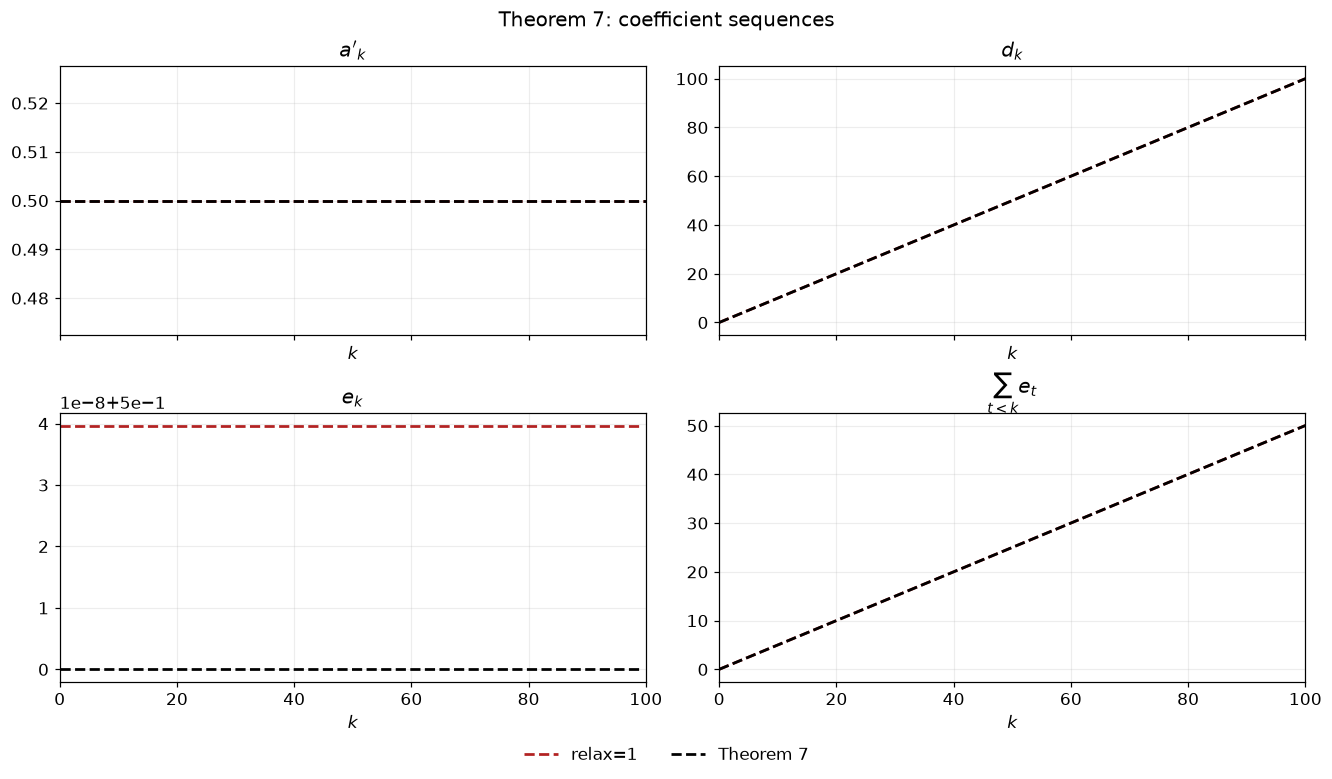

| 계수 | 수치해의 마지막 값 | Theorem 7의 마지막 값 | 수열의 최대 절댓값 차이 |
| --- | --- | --- | --- |
| $a'_k$ | 0.5 | 0.5 | 0.000e+00 |
| $d_k$ | 100 | 100 | 0.000e+00 |
| $e_k$ | 0.50000004 | 0.5 | 3.968e-08 |
| $\sum_{t=0}^{k-1}e_t$ | 50.000004 | 50 | 3.968e-06 |

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for result, label, color, linestyle in (
    (primal_results[1], "relax=1", "firebrick", "--"),
    (analytical_primal, "Theorem 7", "black", "--"),
):
    for ax, key, title in zip(axes.flat, ("ap", "d", "e", "ec"),
                               (r"$a'_k$", r"$d_k$", r"$e_k$", r"$\sum_{t<k}e_t$")):
        iterations = np.arange(N) if key == "e" else np.arange(N + 1)
        ax.plot(iterations, result[key], color=color, linestyle=linestyle, linewidth=1.8, label=label)
        ax.set(title=title, xlim=(0, N), xlabel=r"$k$")
fig.suptitle("Theorem 7: coefficient sequences")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()
coefficient_labels = {"ap": r"$a'_k$", "d": r"$d_k$", "e": r"$e_k$", "ec": r"$\sum_{t=0}^{k-1}e_t$"}
headers = ["계수", "수치해의 마지막 값", "Theorem 7의 마지막 값", "수열의 최대 절댓값 차이"]
rows = [[coefficient_labels[key], f"{primal_results[1][key][-1]:.8g}", f"{analytical_primal[key][-1]:.8g}",
         f"{np.max(np.abs(primal_results[1][key] - analytical_primal[key])):.3e}"]
        for key in ("ap", "d", "e", "ec")]
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
lines = lines + ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

#### 명시적 multiplier로 LMI를 구성하기

$\delta_k=1/L$, $d_k=k$에서

$$\lambda_{\star,y_{k+1}}=1,\qquad\lambda_{y_k,y_{k+1}}=k$$

이며 나머지는 0이다. 원본 2C 계수벡터를 대입하면

$$\frac1n\sum_iV_{k+1}^{(i)}-V_k-e_kA_{\rm var}+\sum_{i\ne j}\lambda_{i,j}M_{i,j}
=-\frac{k}{2L}(\mathtt{gyk1}-\mathtt{gyk})(\mathtt{gyk1}-\mathtt{gyk})^\top\preceq0.$$

함수값 계수도

$$-k\mathtt{fyk}+(k+1)\mathtt{fyk1}-\mathtt{fyk1}
+k(\mathtt{fyk}-\mathtt{fyk1})=0$$

으로 소거된다. 아래에서는 이를 원래 5×5 LMI에 대입한다.


In [33]:
R_primal, equality_primal, expected_primal, weights_primal = [], [], [], []
for k in range(1, N + 1):
    d_current = analytical_primal["d"][k - 1]
    X = {1: xs, 2: yk, 3: yk1(d_current, k)}
    G = {1: gxs, 2: gyk, 3: gyk1}
    F = {1: fxs, 2: fyk, 3: fyk1}
    weights = np.zeros((nbPts, nbPts))
    weights[0, 2] = 1
    weights[1, 2] = k - 1
    R = -L / 2 * np.outer(xk - xs, xk - xs) - analytical_primal["e"][k - 1] * Avar
    equality = -d_current * fyk + analytical_primal["d"][k] * fyk1
    XK1 = xk1(k)
    for i in range(1, n + 1):
        R = R + L / (2 * n) * np.outer(XK1[i - 1] - xs, XK1[i - 1] - xs)
    for i in range(1, nbPts + 1):
        for j in range(1, nbPts + 1):
            if j != i:
                TT = np.vstack((X[i], X[j], G[i], G[j]))
                R = R + weights[i - 1, j - 1] * (TT.T @ M @ TT)
                equality = equality + weights[i - 1, j - 1] * (F[i] - F[j])
    R_primal.append(R)
    equality_primal.append(equality)
    weights_primal.append(weights)
    expected_primal.append(-(k - 1) / (2 * L) * np.outer(gyk1 - gyk, gyk1 - gyk))

In [34]:
check_primal = {
    "R": np.asarray(R_primal), "equality": np.asarray(equality_primal),
    "lmi_violation": float(max(0., np.linalg.eigvalsh(R_primal).max())),
    "equality_violation": float(np.max(np.abs(equality_primal))),
    "multiplier_violation": float(max(0., -np.min(weights_primal))),
    "matrix_identity_error": float(np.max(np.abs(np.asarray(R_primal) - expected_primal))),
}

print(f"Theorem 7: matrix identity error={check_primal['matrix_identity_error']:.3e}")


Theorem 7: matrix identity error=1.138e-15


#### Appendix E.3 — 평균 갱신식이 교차항을 소거하는 과정

현재 상태를 고정한 조건부 기대값을 $\mathbb E_i$로 쓴다. 평균점 $y_{k+1}$은 oracle 호출 전에 정해지며,

$$(d_k+L\delta_k)y_{k+1}=d_ky_k+L\delta_kx_k$$

를 만족한다. $x_\star,y_{k+1}$ 및 $y_k,y_{k+1}$ 사이의 interpolation 부등식에 각각 $L\delta_k,d_k$를 곱하면, 내적항은

$$\begin{aligned}
&L\delta_k
\langle f'(y_{k+1}),y_{k+1}-x_\star\rangle
-d_k\langle f'(y_{k+1}),y_k-y_{k+1}\rangle\\
&=L\delta_k\langle f'(y_{k+1}),x_k-x_\star\rangle
\end{aligned}$$

로 모인다. 한편 SGD 갱신식에서 거리항을 전개하고 unbiasedness를 사용하면

$$\begin{aligned}
&\frac L2\left(
\mathbb E_i\|x_{k+1}^{(i)}-x_\star\|^2-\|x_k-x_\star\|^2
\right)\\
&=-L\delta_k\langle f'(y_{k+1}),x_k-x_\star\rangle
+\frac{L\delta_k^2}{2}\mathbb E_i\|G(y_{k+1};i)\|^2.
\end{aligned}$$

두 식을 더하면 위치와 gradient 사이의 내적이 소거된다. Oracle 출력의 norm 제곱항에는

$$\mathbb E_i\|G(y_{k+1};i)\|^2
=\|f'(y_{k+1})\|^2
+\mathbb E_i\|G(y_{k+1};i)-f'(y_{k+1})\|^2$$

를 사용한다. 함수값 항은 $d_{k+1}=d_k+L\delta_k$에 의해 다음·현재 potential의 차이로 정리된다. 이들을 합하면

$$\begin{aligned}
&\mathbb E_i\phi_{k+1}^f-\phi_k^f
-\frac{L\delta_k^2}{2}
\mathbb E_i\|G(y_{k+1};i)-f'(y_{k+1})\|^2\\
&\qquad+L\delta_k\left[f_\star-f(y_{k+1})-\langle f'(y_{k+1}),x_\star-y_{k+1}\rangle-\frac1{2L}\Vert f'(y_{k+1})\Vert^2\right]
+d_k\left[f(y_k)-f(y_{k+1})-\langle f'(y_{k+1}),y_k-y_{k+1}\rangle-\frac1{2L}\Vert f'(y_k)-f'(y_{k+1})\Vert^2\right]\\
&=-\frac{\delta_k}{2}(1-L\delta_k)
\|f'(y_{k+1})\|^2
-\frac{d_k}{2L}
\|f'(y_{k+1})-f'(y_k)\|^2
\le0.
\end{aligned}$$

$d_k\ge0$, $0\le\delta_k\le1/L$이면 마지막 두 항은 모두 0 이하다. Interpolation 부등식의 항들은 비음수이고 oracle의 분산은 $\sigma^2$ 이하이므로

$$\mathbb E_i\phi_{k+1}^f-\phi_k^f
\le\frac{L\delta_k^2}{2}
\mathbb E_i\|G(y_{k+1};i)-f'(y_{k+1})\|^2
\le\frac{L\delta_k^2}{2}\sigma^2.$$

따라서 $e_k=L\delta_k^2/2$이면 충분하다. 평균점을 oracle 평가점으로 사용한 덕분에, Theorem 6에서 필요했던 추가항 없이 교차항을 정리할 수 있었다.

$\delta_k=1/L$, $d_0=0$이면 $y_N=N^{-1}\sum_{t=0}^{N-1}x_t$이다. 한 단계 부등식에 전체 기대값을 취해 합하면

$$N\mathbb E[f(y_N)-f_\star]
+\frac L2\mathbb E\|x_N-x_\star\|^2
\le\frac L2\|x_0-x_\star\|^2+\frac N{2L}\sigma^2$$

를 얻는다. 따라서 최종 함수값 상한은

$$\boxed{\mathbb E[f(y_N)-f_\star]
\le\frac{L\|x_0-x_\star\|^2}{2N}+\frac{\sigma^2}{2L}}$$

이다.


## 종합 비교 · Table 2

이후에는 SDP를 다시 풀지 않고 각 정리의 계수 합을 평가한다.

### 고정 step-size에서 세 방법을 비교하기

$\delta_k=1/L$이고 초기 함수값 계수가 0이면 세 정리의 최종 함수값 계수는 $N$이다. 각 출력 $x_N,z_N,y_N$에서 초기 거리 항은 $L\|x_0-x_\star\|^2/(2N)$이고, 분산 항은 $\sigma^2(\sum_{k<N}e_k)/N$이다.

| 방법 | $e_k$ | $\sum_{k<N}e_k$ | $(\sum_{k<N}e_k)/N$ |
| --- | --- | --- | --- |
| SGD, Theorem 5 | $(k+2)/(2L)$ | $N(N+3)/(4L)$ | $(N+3)/(4L)$ |
| Averaging, Theorem 6 | $(1+1/(k+1))/(2L)$ | $(N+\sum_{j=1}^N1/j)/(2L)$ | $(1+N^{-1}\sum_{j=1}^N1/j)/(2L)$ |
| Primal averaging, Theorem 7 | $1/(2L)$ | $N/(2L)$ | $1/(2L)$ |

초기 거리 항은 공통이므로, 이 비교의 차이는 분산에 곱해지는 마지막 열의 계수에서 생긴다.


In [35]:
transitions = np.arange(N_FIGURE)
constant_results = {
    "SGD / Theorem 5": {"e": (transitions + 2) / (2 * L)},
    "Averaging / Theorem 6": analytical_avg,
    "Primal / Theorem 7": analytical_primal,
}
constant_results["SGD / Theorem 5"]["ec"] = np.r_[
    0., np.cumsum(constant_results["SGD / Theorem 5"]["e"])]
constant_colors = {
    "SGD / Theorem 5": "saddlebrown",
    "Averaging / Theorem 6": "royalblue",
    "Primal / Theorem 7": "purple",
}
H_N = np.sum(1 / np.arange(1, N_FIGURE + 1))
closed_sums = [N_FIGURE * (N_FIGURE + 3) / (4 * L),
               (N_FIGURE + H_N) / (2 * L), N_FIGURE / (2 * L)]
headers = ["방법", r"$\sum e_k$", "명시적 합", r"Variance coefficient", r"초기 거리 계수"]
rows = [(label, f"{r['ec'][-1]:.8g}", f"{closed:.8g}",
         f"{r['ec'][-1] / N_FIGURE:.8g}", f"{L / (2 * N_FIGURE):.8g}")
        for (label, r), closed in zip(constant_results.items(), closed_sums)]
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| 방법 | $\sum e_k$ | 명시적 합 | Variance coefficient | 초기 거리 계수 |
| --- | --- | --- | --- | --- |
| SGD / Theorem 5 | 2575 | 2575 | 25.75 | 0.005 |
| Averaging / Theorem 6 | 52.593689 | 52.593689 | 0.52593689 | 0.005 |
| Primal / Theorem 7 | 50 | 50 | 0.5 | 0.005 |

다음 세 패널은 $e_k$, $\sum_{k<N}e_k$, $(\sum_{k<N}e_k)/N$을 차례로 보여 준다. 마지막 계수는 SGD에서 $\Theta(N)$이고 두 평균법에서 $1/(2L)$로 수렴한다. 전체 그림을 본 뒤 두 평균법만 확대한다.

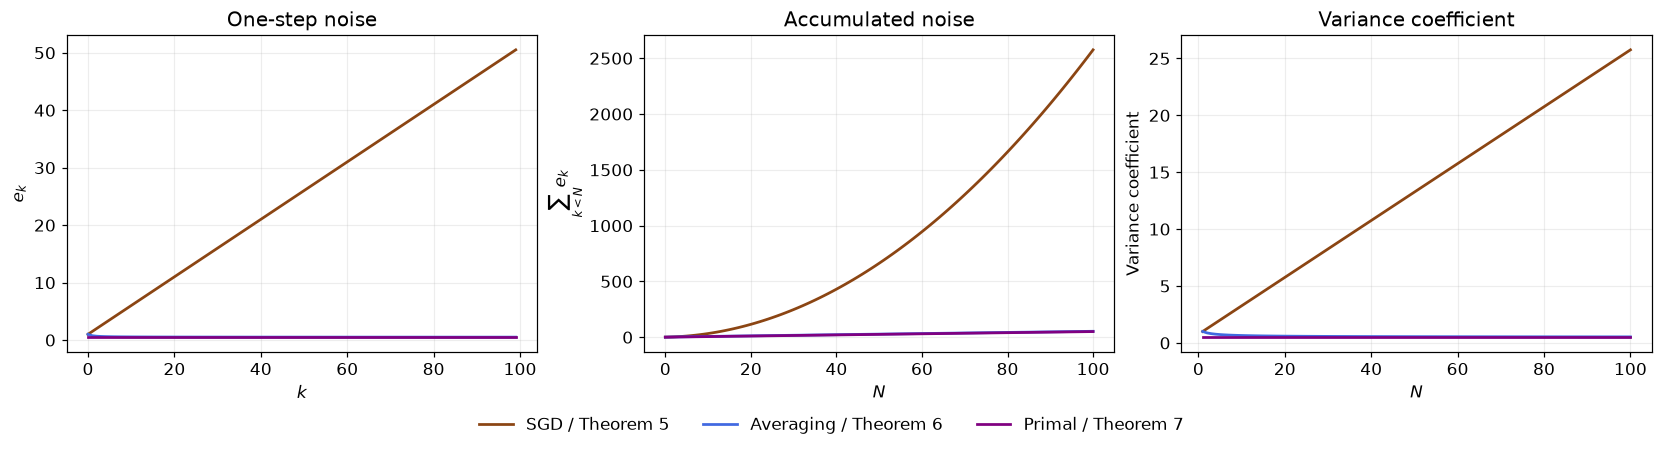

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for label, r in constant_results.items():
    axes[0].plot(np.arange(N_FIGURE), r["e"], color=constant_colors[label],
                 linewidth=1.8, label=label)
    axes[1].plot(np.arange(N_FIGURE + 1), r["ec"], color=constant_colors[label],
                 linewidth=1.8, label=label)
    axes[2].plot(np.arange(1, N_FIGURE + 1),
                 r["ec"][1:] / np.arange(1, N_FIGURE + 1),
                 color=constant_colors[label], linewidth=1.8, label=label)
axes[0].set(xlabel=r"$k$", ylabel=r"$e_k$", title="One-step noise")
axes[1].set(xlabel=r"$N$", ylabel=r"$\sum_{k<N}e_k$",
            title="Accumulated noise")
axes[2].set(xlabel=r"$N$", ylabel=r"Variance coefficient",
            title="Variance coefficient")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

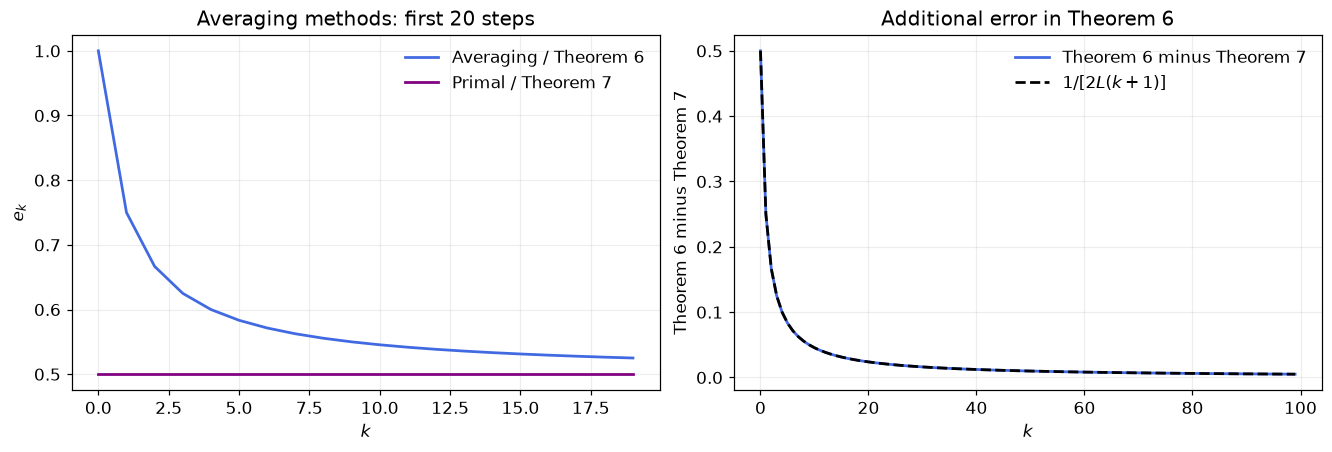

In [37]:
zoom_end = min(20, N_FIGURE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for label in ("Averaging / Theorem 6", "Primal / Theorem 7"):
    result = constant_results[label]
    axes[0].plot(np.arange(zoom_end), result["e"][:zoom_end],
                 color=constant_colors[label], linewidth=1.8, label=label)
difference = analytical_avg["e"] - analytical_primal["e"]
axes[1].plot(transitions, difference, color="royalblue", linewidth=1.8,
             label=r"Theorem 6 minus Theorem 7")
axes[1].plot(transitions, 1 / (2 * L * (transitions + 1)),
             color="black", linestyle="--", linewidth=1.8,
             label=r"$1/[2L(k+1)]$")
axes[0].set(xlabel=r"$k$", ylabel=r"$e_k$", title="Averaging methods: first 20 steps")
axes[1].set(xlabel=r"$k$", ylabel=r"Theorem 6 minus Theorem 7",
            title="Additional error in Theorem 6")
for ax in axes:
    ax.legend(frameon=False)
plt.show()


두 평균법의 단계별 오차 계수 차이는

$$\frac1{2L}\left(1+\frac1{k+1}\right)-\frac1{2L}=\frac1{2L(k+1)}$$

이다. Averaging은 SGD의 오차 계수 증가를 억제하고, primal averaging은 이 추가항도 제거한다. 다만 고정 step-size에서 $(\sum_{k<N}e_k)/N$은 0으로 가지 않으므로, 감소 step-size의 계수 합도 살펴본다.

### 감소 step-size와 Appendix E.5의 가중평균

세 방법에 $\delta_k=1/[L(k+1)^\alpha]$를 적용한다. Theorem 5와 7의 함수값 계수는 논문의 $d_{k+1}=d_k+L\delta_k$를 따른다.

Theorem 6은 Appendix E.5 p.44의 **논문 표기**를 그대로 사용한다.

$$d_0=0,\qquad d_{k+1}=\frac{\delta_k}{\delta_{k+1}}(d_k+1),\qquad
D_0=0,\quad D_k=L\delta_{k-1}(d_{k-1}+1)=L\delta_kd_k.$$

여기서 $d_k$는 평균 가중치, $D_k$는 함수값 계수다. 따라서

$$D_{k+1}=D_k+L\delta_k,\qquad
z_{k+1}^{(i)}=\frac{D_kz_k+L\delta_kx_{k+1}^{(i)}}{D_{k+1}},\qquad
z_N=\frac{\sum_{k<N}\delta_kx_{k+1}}{\sum_{k<N}\delta_k}.$$

새 반복점의 가중치는 step-size에 비례한다. $\alpha=0$에서는 산술평균과 같다. A의 수치 SDP는 원본의 산술평균과 1부터 시작하는 `delta(k)`를 사용했고, 이후 계수 합은 $k=0$부터 시작하는 논문의 step-size와 Appendix E.5의 가중평균을 사용한다.


In [38]:
N_RATE = 100_000
Ns = np.unique(np.geomspace(10, N_RATE, 70).astype(int))
alphas = (0.0, 0.5, 2 / 3, 0.8)
methods = ("sgd", "averaging", "primal")
method_labels = {
    "sgd": "SGD / Theorem 5",
    "averaging": "Weighted averaging / Theorem 6",
    "primal": "Primal averaging / Theorem 7",
}
method_colors = {"sgd": "saddlebrown", "averaging": "royalblue", "primal": "purple"}

각 정리의 오차 계수는 다음과 같다. $D_k$는 앞 셀의 Theorem 6에만 사용한다.

| 정리 | $e_k$ | 최종 함수값 계수 |
| --- | --- | --- |
| Theorem 5 | $L\delta_k^2(1+d_{k+1})/2$ | $d_N=\sum_{k<N}L\delta_k$ |
| Theorem 6 | $\frac{L\delta_k^2}{2}(1+L^2\delta_k^2/D_{k+1})$ | $D_N=\sum_{k<N}L\delta_k$ |
| Theorem 7 | $L\delta_k^2/2$ | $d_N=\sum_{k<N}L\delta_k$ |

모두 최종 함수값 계수가 $\sum_{k<N}L\delta_k$로 같다. 두 평균법은 각각 갱신 후·갱신 전 점을 평균에 사용하고, oracle 평가점도 다르다. 아래 코드는 각 정리의 계수와 합을 계산한다.


In [39]:
rate_results = {}
for alpha in alphas:
    delta_state = 1 / (L * (np.arange(N_RATE + 1, dtype=float) + 1)**alpha)
    delta = delta_state[:-1]
    q = L * delta
    d = np.r_[0., np.cumsum(q)]
    step_errors = {
        "sgd": L * delta**2 * (1 + d[1:]) / 2,
        "averaging": L * delta**2 * (1 + q**2 / d[1:]) / 2,
        "primal": L * delta**2 / 2,
    }
    for method in methods:
        e = step_errors[method]
        m = d / (L * delta_state) if method == "averaging" else d.copy()
        new_weight = np.ones(N_RATE) if method == "sgd" else q / d[1:]
        rate_results[method, alpha] = {
            "method": method, "N": N_RATE, "L": L, "alpha": alpha,
            "delta": delta, "d": d, "m": m, "e": e,
            "ec": np.r_[0., np.cumsum(e)], "new_weight": new_weight,
        }

한 단계 부등식을 합하면 각 출력 $x_N,z_N,y_N$의 함수값 상한은

$$\frac{L\|x_0-x_\star\|^2}{2\sum_{k<N}L\delta_k}
+\frac{\sum_{k<N}e_k}{\sum_{k<N}L\delta_k}\sigma^2$$

이다. 아래 그림은 $\|x_0-x_\star\|^2=\sigma^2=1$에서 위쪽에 분산의 계수, 아래쪽에 전체 상한을 표시한다. 코드는 이를 `bound_distance`, `bound_variance`에 저장한다. Step-size를 빨리 줄이면 오차 계수의 합과 함수값 계수 모두 작아지므로 두 효과를 함께 비교한다.


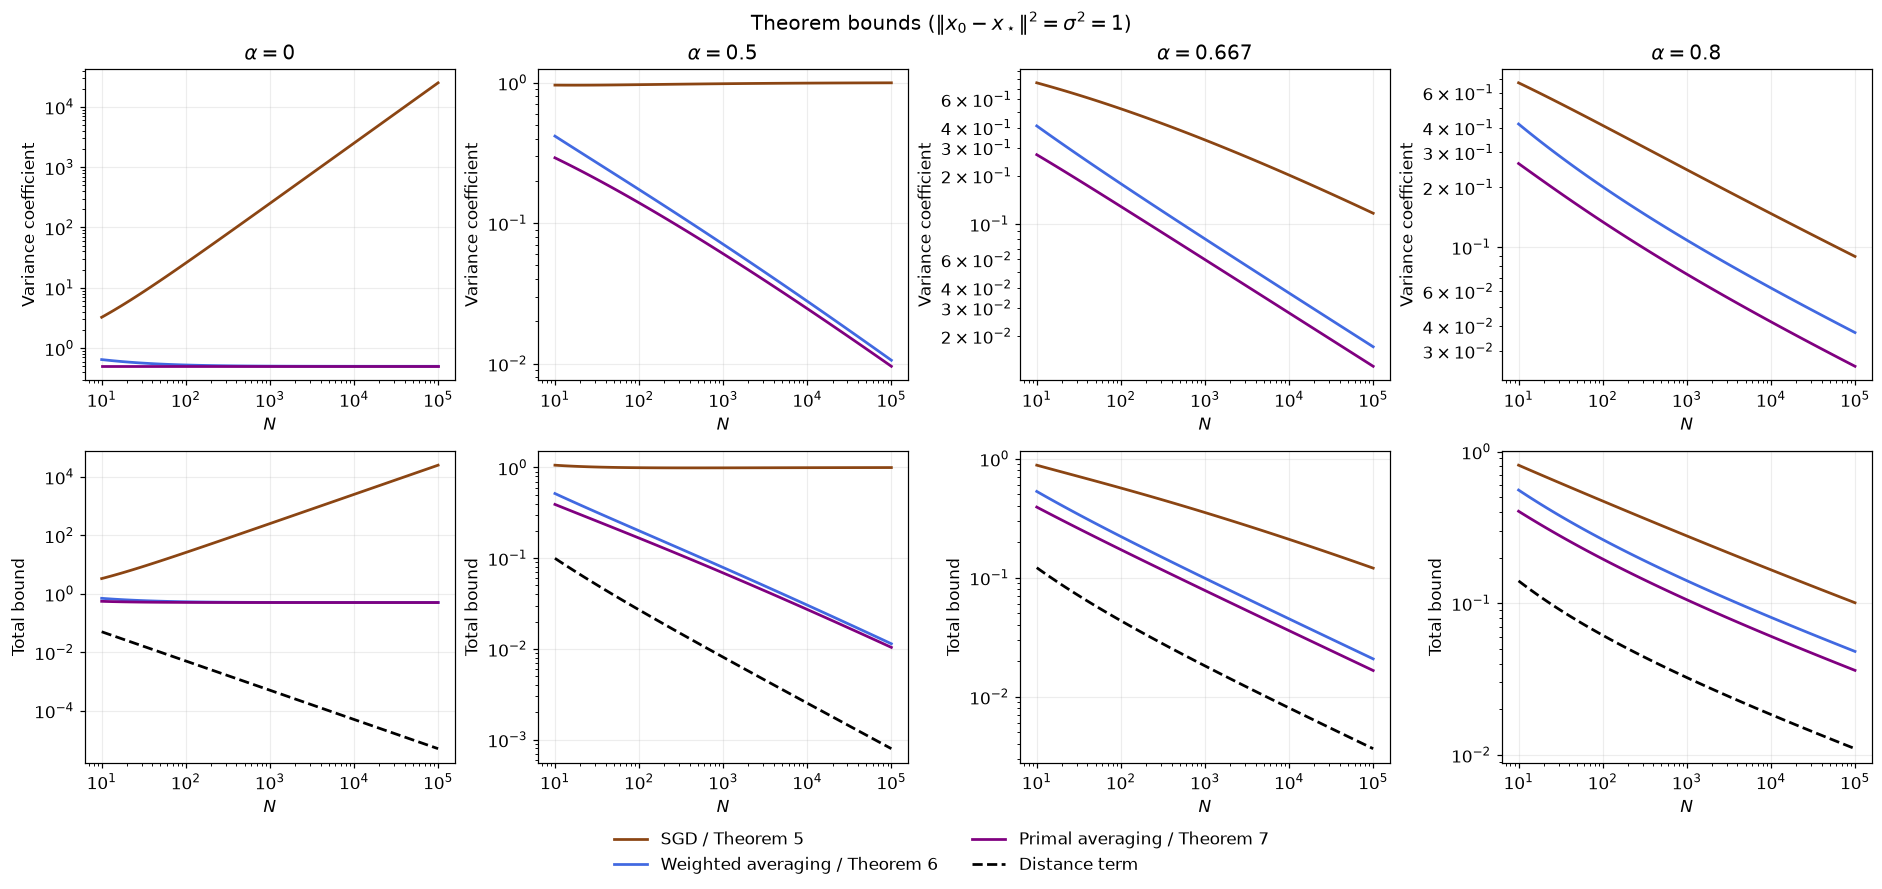

In [40]:
for r in rate_results.values():
    r["bound_distance"] = np.r_[np.nan, L / (2 * r["d"][1:])]
    r["bound_variance"] = np.r_[np.nan, r["ec"][1:] / r["d"][1:]]

fig, axes = plt.subplots(2, 4, figsize=(17, 8), layout="constrained")
for column, alpha in enumerate(alphas):
    for method in methods:
        r = rate_results[method, alpha]
        axes[0, column].loglog(Ns, r["bound_variance"][Ns],
                              color=method_colors[method], linewidth=1.8,
                              label=method_labels[method])
        axes[1, column].loglog(Ns,
                              r["bound_distance"][Ns] + r["bound_variance"][Ns],
                              color=method_colors[method], linewidth=1.8,
                              label=method_labels[method])
    axes[1, column].loglog(Ns, rate_results["sgd", alpha]["bound_distance"][Ns],
                          color="black", linestyle="--", linewidth=1.8,
                          label="Distance term")
    axes[0, column].set(title=rf"$\alpha={alpha:.3g}$",
                        xlabel=r"$N$", ylabel=r"Variance coefficient")
    axes[1, column].set(xlabel=r"$N$", ylabel=r"Total bound")
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(r"Theorem bounds ($\|x_0-x_\star\|^2=\sigma^2=1$)")
plt.show()

분산 계수의 감소 속도는 사용한 $N$ 가운데 가장 큰 8개에서 `np.polyfit`으로 추정한다. 로그를 취한 분산 계수와 $N$ 사이의 기울기를 구간별 식과 비교하고, 임계점에서 로그 인자가 만드는 차이를 확인한다.

In [41]:
headers = [r"$\alpha$", "방법", r"$\sum_{k<N}L\delta_k$", r"초기 거리 계수", r"Variance coefficient",
           r"Total bound", r"분산 계수의 log–log 기울기"]
rows = []
for (method, alpha), r in rate_results.items():
    slope, intercept = np.polyfit(np.log(Ns[-8:]),
                                 np.log(r["bound_variance"][Ns[-8:]]), 1)
    rows.append((f"{alpha:.4g}", method_labels[method], f"{r['d'][-1]:.6g}",
                 f"{r['bound_distance'][-1]:.6g}",
                 f"{r['bound_variance'][-1]:.6g}",
                 f"{r['bound_distance'][-1] + r['bound_variance'][-1]:.6g}",
                 f"{slope:.4f}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| $\alpha$ | 방법 | $\sum_{k<N}L\delta_k$ | 초기 거리 계수 | Variance coefficient | Total bound | 분산 계수의 log–log 기울기 |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | SGD / Theorem 5 | 100000 | 5e-06 | 25000.8 | 25000.8 | 1.0000 |
| 0 | Weighted averaging / Theorem 6 | 100000 | 5e-06 | 0.50006 | 0.500065 | -0.0002 |
| 0 | Primal averaging / Theorem 7 | 100000 | 5e-06 | 0.5 | 0.500005 | -0.0000 |
| 0.5 | SGD / Theorem 5 | 630.997 | 0.000792397 | 0.99658 | 0.997372 | 0.0016 |
| 0.5 | Weighted averaging / Theorem 6 | 630.997 | 0.000792397 | 0.0105805 | 0.0113729 | -0.4238 |
| 0.5 | Primal averaging / Theorem 7 | 630.997 | 0.000792397 | 0.0095802 | 0.0103726 | -0.4154 |
| 0.6667 | SGD / Theorem 5 | 136.8 | 0.00365496 | 0.116631 | 0.120286 | -0.2432 |
| 0.6667 | Weighted averaging / Theorem 6 | 136.8 | 0.00365496 | 0.0171115 | 0.0207665 | -0.3349 |
| 0.6667 | Primal averaging / Theorem 7 | 136.8 | 0.00365496 | 0.0129251 | 0.01658 | -0.3332 |
| 0.8 | SGD / Theorem 5 | 45.5625 | 0.0109739 | 0.0896698 | 0.100644 | -0.2148 |
| 0.8 | Weighted averaging / Theorem 6 | 45.5625 | 0.0109739 | 0.0370779 | 0.0480518 | -0.2212 |
| 0.8 | Primal averaging / Theorem 7 | 45.5625 | 0.0109739 | 0.0250656 | 0.0360395 | -0.2210 |

### Table 2 — 거듭제곱 차수와 로그 인자를 구분하기

Table 2는 초기 거리에서 오는 항과 분산에서 오는 항을 비교한다. 아래 표의 분산 항의 차수는 SGD에서 $0\le\alpha<2/3$, 두 평균법에서 $0\le\alpha<1/2$인 구간에 해당한다. 균형점에서는 $\log N$ 인자가 추가되며, 그보다 큰 $\alpha$에서는 뒤에서 정리할 구간별 식을 적용해야 한다.

| 방법 | 초기 거리 항 | 분산 항 | 균형점 $\alpha$ |
| --- | --- | --- | --- |
| SGD | $O(N^{\alpha-1})$ | $O(N^{1-2\alpha})$ | $2/3$ |
| Averaging | $O(N^{\alpha-1})$ | $O(N^{-\alpha})$ | $1/2$ |
| Primal averaging | $O(N^{\alpha-1})$ | $O(N^{-\alpha})$ | $1/2$ |

이 차수는 각 정리의 유한 합에서 얻는다.

| 정리 | $\sum_{k<N}e_k$ |
| --- | --- |
| Theorem 5 | $\frac1{2L}\sum_{k<N}(L\delta_k)^2(1+\sum_{t=0}^kL\delta_t)$ |
| Theorem 6 | $\frac1{2L}[\sum_{k<N}(L\delta_k)^2+\sum_{k<N}(L\delta_k)^4/(\sum_{t=0}^kL\delta_t)]$ |
| Theorem 7 | $\frac1{2L}\sum_{k<N}(L\delta_k)^2$ |

각 합을 $\sum_{k<N}L\delta_k$로 나누면 함수값 상한의 분산 계수가 된다.


In [42]:
headers = [r"$\alpha$", "방법", r"$\sum_{k<N}L\delta_k$", r"$\sum_{k<N}e_k$", r"$(\sum_{k<N}e_k)/(\sum_{k<N}L\delta_k)$"]
rows = []
for alpha in alphas:
    q = (np.arange(1, N_RATE + 1, dtype=float))**(-alpha)
    d_next = np.cumsum(q)
    noise_sums = {
        "sgd": np.sum(q**2 * (1 + d_next)) / (2 * L),
        "averaging": (np.sum(q**2) + np.sum(q**4 / d_next)) / (2 * L),
        "primal": np.sum(q**2) / (2 * L),
    }
    for method in methods:
        rows.append((f"{alpha:.4g}", method_labels[method], f"{d_next[-1]:.6g}",
                     f"{noise_sums[method]:.6g}",
                     f"{noise_sums[method] / d_next[-1]:.6g}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| $\alpha$ | 방법 | $\sum_{k<N}L\delta_k$ | $\sum_{k<N}e_k$ | $(\sum_{k<N}e_k)/(\sum_{k<N}L\delta_k)$ |
| --- | --- | --- | --- | --- |
| 0 | SGD / Theorem 5 | 100000 | 2.50008e+09 | 25000.8 |
| 0 | Weighted averaging / Theorem 6 | 100000 | 50006 | 0.50006 |
| 0 | Primal averaging / Theorem 7 | 100000 | 50000 | 0.5 |
| 0.5 | SGD / Theorem 5 | 630.997 | 628.839 | 0.99658 |
| 0.5 | Weighted averaging / Theorem 6 | 630.997 | 6.67628 | 0.0105805 |
| 0.5 | Primal averaging / Theorem 7 | 630.997 | 6.04507 | 0.0095802 |
| 0.6667 | SGD / Theorem 5 | 136.8 | 15.9552 | 0.116631 |
| 0.6667 | Weighted averaging / Theorem 6 | 136.8 | 2.34086 | 0.0171115 |
| 0.6667 | Primal averaging / Theorem 7 | 136.8 | 1.76815 | 0.0129251 |
| 0.8 | SGD / Theorem 5 | 45.5625 | 4.08558 | 0.0896698 |
| 0.8 | Weighted averaging / Theorem 6 | 45.5625 | 1.68936 | 0.0370779 |
| 0.8 | Primal averaging / Theorem 7 | 45.5625 | 1.14205 | 0.0250656 |

$0\le\alpha<1$이면 $\sum_{t=0}^kL\delta_t\asymp(k+1)^{1-\alpha}$이므로 초기 거리 항은 $O(N^{\alpha-1})$다. 또한

$$\sum_{k<N}(L\delta_k)^2\sum_{t=0}^kL\delta_t
\asymp\sum_{k<N}(k+1)^{1-3\alpha},\qquad
\sum_{k<N}(L\delta_k)^2=\sum_{k<N}(k+1)^{-2\alpha}.$$

분산 계수의 차수는 다음과 같다.

| 방법 | $\alpha$ 범위 | 분산 계수의 차수 |
| --- | --- | --- |
| SGD | $0\le\alpha<2/3$ | $N^{1-2\alpha}$ |
| SGD | $\alpha=2/3$ | $(\log N)N^{-1/3}$ |
| SGD | $2/3<\alpha<1$ | $N^{\alpha-1}$ |
| 두 평균법 | $0\le\alpha<1/2$ | $N^{-\alpha}$ |
| 두 평균법 | $\alpha=1/2$ | $(\log N)N^{-1/2}$ |
| 두 평균법 | $1/2<\alpha<1$ | $N^{\alpha-1}$ |

두 평균법의 추가합은

$$\sum_{k<N}\frac{(L\delta_k)^4}{\sum_{t=0}^kL\delta_t}
\asymp\sum_{k<N}(k+1)^{-1-3\alpha}$$

이다. $\alpha>0$에서는 유계이고 $\alpha=0$에서는 $\sum_{j=1}^N1/j$다. 두 평균법의 지배적인 차수는 같다. $\alpha=0.8$에서 세 방법 모두 $N^{-0.2}$이고, $\alpha=1$에서는 초기 거리 계수와 분산 계수 모두 $\Theta(1/\log N)$, $\alpha>1$에서는 $\Theta(1)$이다.


임계점에서 SGD의 분산 계수는 $(\log N)N^{-1/3}$, 두 평균법은 $(\log N)N^{-1/2}$ 차수다. 다음 그림은 각각 $N^{1/3}$, $N^{1/2}$를 곱한 값과 거기에 $\log N$을 한 번 더 나눈 값을 비교한다. 거듭제곱만 제거한 값에는 로그 증가가 남고, 로그까지 나눈 값은 상수에 가까워진다.

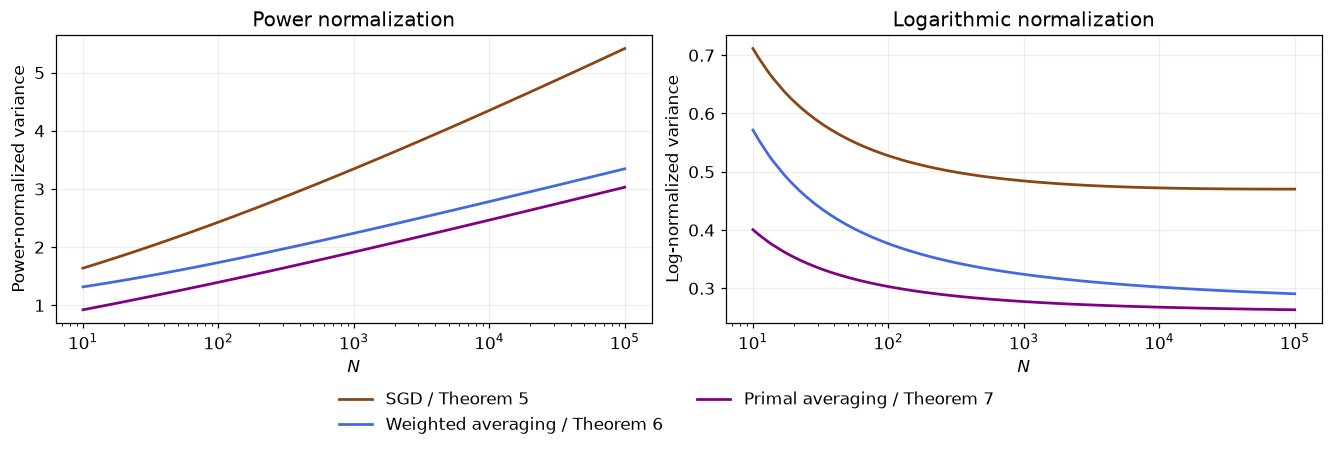

In [43]:
critical = {"sgd": 2 / 3, "averaging": 0.5, "primal": 0.5}
power = {"sgd": 1 / 3, "averaging": 0.5, "primal": 0.5}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for method in methods:
    r = rate_results[method, critical[method]]
    scaled = r["bound_variance"][Ns] * Ns**power[method]
    axes[0].semilogx(Ns, scaled, color=method_colors[method],
                     linewidth=1.8, label=method_labels[method])
    axes[1].semilogx(Ns, scaled / np.log(Ns), color=method_colors[method],
                     linewidth=1.8, label=method_labels[method])
axes[0].set(xlabel=r"$N$", ylabel=r"Power-normalized variance",
            title="Power normalization")
axes[1].set(xlabel=r"$N$", ylabel=r"Log-normalized variance",
            title="Logarithmic normalization")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()

임계점의 log–log 기울기는 SGD에서 대략 $-1/3+1/\log N$, 두 평균법에서 $-1/2+1/\log N$이다. 유한 구간의 기울기는 점근적 지수보다 크고 천천히 접근한다. 다음 표는 기울기와 로그까지 나누어 정규화한 분산 계수를 함께 보여 준다.

In [44]:
headers = ["방법", r"$\alpha$", r"거듭제곱 차수", "log–log 기울기", r"Log-normalized variance"]
rows = []
for method in methods:
    variance = rate_results[method, critical[method]]["bound_variance"]
    slope, intercept = np.polyfit(np.log(Ns[-8:]), np.log(variance[Ns[-8:]]), 1)
    normalized = N_RATE**power[method] * variance[-1] / np.log(N_RATE)
    rows.append((method_labels[method], f"{critical[method]:.6g}", f"{power[method]:.6g}",
                 f"{slope:.5f}", f"{normalized:.6g}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| 방법 | $\alpha$ | 거듭제곱 차수 | log–log 기울기 | Log-normalized variance |
| --- | --- | --- | --- | --- |
| SGD / Theorem 5 | 0.666667 | 0.333333 | -0.24321 | 0.470213 |
| Weighted averaging / Theorem 6 | 0.5 | 0.5 | -0.42384 | 0.290617 |
| Primal averaging / Theorem 7 | 0.5 | 0.5 | -0.41540 | 0.263141 |

### 두 항의 균형으로 step-size 지수를 선택하기

로그를 제외하면 SGD 전체 상한의 거듭제곱 지수는 $\min\{1-\alpha,2\alpha-1\}$, 두 평균법은 $\min\{1-\alpha,\alpha\}$다. 두 항을 균형 잡는 선택은

$$1-\alpha=2\alpha-1\ \Longrightarrow\ \alpha=2/3,\qquad
1-\alpha=\alpha\ \Longrightarrow\ \alpha=1/2$$

이다. Table 2에서 로그를 제외한 수렴률이 각각 $O(N^{-1/3})$, $O(N^{-1/2})$인 이유다.

주어진 $N$에서 유한 합을 최소화하는 $\alpha$는 상수에도 의존한다. 아래에서는 $N=10^5$, $\|x_0-x_\star\|^2=\sigma^2=1$에서 거듭제곱 지수와 실제 유한 합의 상한을 함께 비교한다.


In [45]:
alpha_grid = np.linspace(0., 0.95, 96)
polynomial_sgd = np.minimum(1 - alpha_grid, 2 * alpha_grid - 1)
polynomial_avg = np.minimum(1 - alpha_grid, alpha_grid)
finite_bounds = {method: [] for method in methods}
for alpha in alpha_grid:
    q = np.arange(1, N_RATE + 1, dtype=float)**(-alpha)
    d_next = np.cumsum(q)
    distance = L / (2 * d_next[-1])
    noise_sums = {
        "sgd": np.sum(q**2 * (1 + d_next)) / (2 * L),
        "averaging": (np.sum(q**2) + np.sum(q**4 / d_next)) / (2 * L),
        "primal": np.sum(q**2) / (2 * L),
    }
    for method in methods:
        finite_bounds[method].append(distance + noise_sums[method] / d_next[-1])

왼쪽은 거듭제곱 지수이고, 오른쪽은 유한 합으로 계산한 전체 상한이다. 왼쪽에서 지수가 가장 큰 지점과 오른쪽에서 상한이 가장 작은 지점을 비교한다.

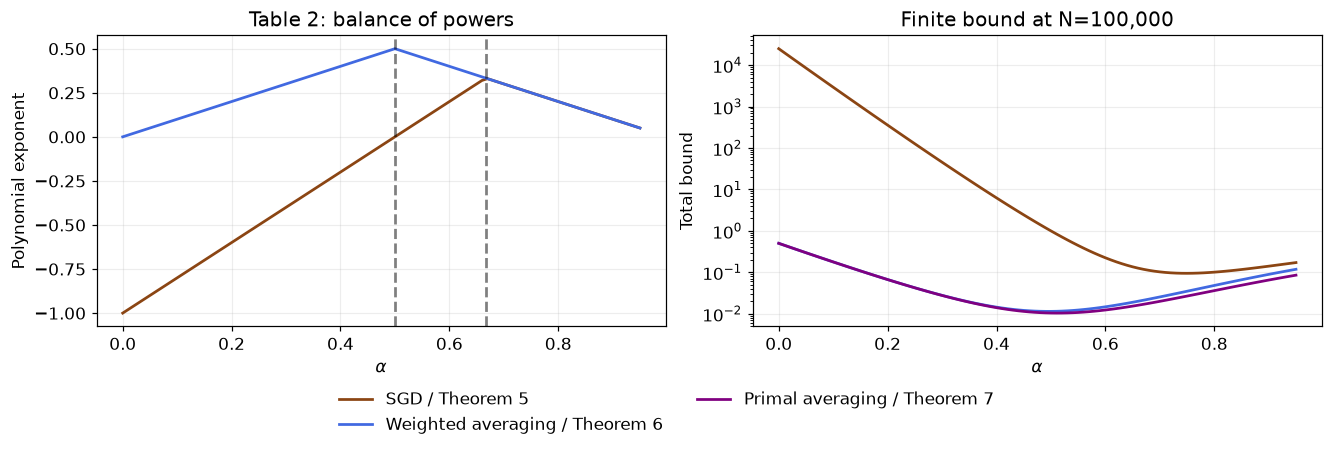

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(alpha_grid, polynomial_sgd, color="saddlebrown",
             linewidth=1.8, label="SGD")
axes[0].plot(alpha_grid, polynomial_avg, color="royalblue",
             linewidth=1.8, label="Averaging and primal averaging")
axes[0].axvline(2 / 3, color="black", linestyle="--", linewidth=1.8, alpha=0.5)
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1.8, alpha=0.5)
axes[0].set(xlabel=r"$\alpha$", ylabel=r"Polynomial exponent",
            title="Table 2: balance of powers")
for method in methods:
    axes[1].semilogy(alpha_grid, finite_bounds[method], color=method_colors[method],
                     linewidth=1.8, label=method_labels[method])
axes[1].set(xlabel=r"$\alpha$", ylabel=r"Total bound",
            title=f"Finite bound at N={N_RATE:,}")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
plt.show()

다음 표에서는 $\alpha\in\{0,0.01,\ldots,0.95\}$를 탐색해 유한 합의 상한이 가장 작은 값을 구하고, Table 2의 점근적 균형점과 비교한다.

In [47]:
headers = ["방법", r"격자의 최적 $\alpha$", "유한 합의 상한", r"Table 2의 $\alpha$"]
rows = []
for method in methods:
    best = np.argmin(finite_bounds[method])
    rows.append((method_labels[method], f"{alpha_grid[best]:.2f}",
                 f"{finite_bounds[method][best]:.6g}", f"{critical[method]:.6g}"))
display(Markdown("| " + " | ".join(headers) + " |\n"
                 + "| " + " | ".join(["---"] * len(headers)) + " |\n"
                 + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

| 방법 | 격자의 최적 $\alpha$ | 유한 합의 상한 | Table 2의 $\alpha$ |
| --- | --- | --- | --- |
| SGD / Theorem 5 | 0.75 | 0.0944023 | 0.666667 |
| Weighted averaging / Theorem 6 | 0.50 | 0.0113729 | 0.5 |
| Primal averaging / Theorem 7 | 0.51 | 0.0103387 | 0.5 |

이 격자에서는 $N=10^5$의 상한이 SGD에서 $\alpha=0.75$, averaging에서 $0.50$, primal averaging에서 $0.51$일 때 가장 작다. SGD의 $0.75$는 상수와 로그의 영향까지 포함한 유한 합을 최소화한 값이다. Table 2의 $2/3$은 초기 거리 항과 분산 항의 점근적인 거듭제곱 지수를 균형 잡는 값이므로, 두 결과가 같을 필요는 없다.

두 평균법의 유한 $N$ 최소점은 점근적 균형점 $1/2$ 부근에 있다. 앞의 임계점 실험에서 본 로그 보정과 유한 합의 상수를 반영하면, 가까운 격자점 사이에서도 최소점이 달라질 수 있다.

지금까지 비교한 세 방법의 차이는 오차 계수에서 드러난다. 고정 step-size의 SGD에서는 함수값 계수가 커지는 동안 오차 계수도 함께 증가했다. Averaging은 그 증가를 억제했고, primal averaging은 평균점에서 oracle을 평가해 추가항까지 제거했다. 이 차이로 감소 step-size에서 선택할 $\alpha$가 바뀌며, 각 정리가 보장하는 수렴률도 $\widetilde O(N^{-1/3})$에서 $\widetilde O(N^{-1/2})$로 개선된다.


전체 분석은 GD의 $\phi_{k+1}^f\le\phi_k^f$에서 SGD와 두 평균법의 $\mathbb E_i\phi_{k+1}^f\le\phi_k^f+e_k\sigma^2$로 확장된다. 각 알고리즘에서 SDP로 탐색한 계수 구조를 Theorem 3·5·6·7의 명시적 수열과 비교했고, 마지막으로 각 정리의 최종 함수값 계수 및 $\sum e_k$의 점근 차수를 통해 Table 2를 도출했다.
